# Aprendizaje no supervisado: modelado y análisis de clusters

En la notebook anterior construimos una tabla con un perfil por pozo. Cada fila representa un pozo y las columnas resumen su comportamiento productivo, su historial y algunas características físicas.

En esta notebook aplicaremos un modelo de clustering para identificar grupos de pozos con perfiles similares.

El algoritmo principal será DBSCAN, ya que permite encontrar grupos basados en densidad y detectar pozos atípicos como ruido. Antes de aplicarlo, transformaremos y escalaremos las variables para que las diferencias de magnitud no distorsionen las distancias.

Como complemento, en la sección 12 aplicamos un segundo algoritmo, el **clustering jerárquico aglomerativo**, sobre las mismas variables, y comparamos sus resultados con los de DBSCAN.

### Importación de librerías

Importamos las librerías necesarias para cargar los perfiles, transformar las variables, calcular distancias, aplicar DBSCAN y evaluar los agrupamientos obtenidos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

sns.set_theme(style="whitegrid")

## 1. Carga y revisión de los perfiles

Cargamos la tabla generada en la notebook anterior. Cada fila representa un pozo y las columnas contienen variables agregadas que resumen su comportamiento histórico, productivo y físico.

En esta etapa verificamos que el archivo se haya generado correctamente y que no existan duplicados ni valores faltantes en las variables que utilizaremos inicialmente.

In [2]:
RUTA_PROCESSED = Path("..") / "data" / "processed"
RUTA_PERFILES = RUTA_PROCESSED / "perfiles_pozos_clustering.csv"

perfiles_pozos = pd.read_csv(
    RUTA_PERFILES,
    parse_dates=["primer_registro", "ultimo_registro"],
    low_memory=False,
)

print(f"Filas: {len(perfiles_pozos):,}")
print(f"Columnas: {perfiles_pozos.shape[1]}")
print(f"Pozos únicos: {perfiles_pozos['idpozo'].nunique():,}")

display(perfiles_pozos.head())

Filas: 4,839
Columnas: 29
Pozos únicos: 4,839


,idpozo,sigla,meses_observados,primer_registro,ultimo_registro,produccion_media,produccion_mediana,produccion_maxima,produccion_acumulada,desvio_produccion,meses_productivos,porcentaje_meses_productivos,produccion_ultimo_mes,produccion_media_3m,produccion_media_6m,cambio_reciente,meses_desde_inicio,profundidad,cota,tef,tipoestado,tipoextraccion,tipopozo,empresa,cuenca,provincia,formacion,sub_tipo_recurso,tipo_terminacion_ultima
0,3640,PPC.Nq.EC-4,246,2006-02-01,2026-07-01,60.072,51.637,164.532,"14,777.817",34.723,241,97.967,0.001,15.776,21.609,-5.832,245,"2,585.000",555.600,0.002,Extracción Efectiva,Bombeo Mecánico,Petrolífero,TANGO ENERGY ARGENTINA S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
1,8043,YPF.Nq.FP.x-2,246,2006-01-01,2026-07-01,1.967,0.000,82.930,483.900,10.109,15,6.098,0.000,0.000,0.000,0.000,246,"3,243.000",463.400,0.000,Parado Transitoriamente,Sin Sistema de Extracción,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
2,10073,CSJ.RN.LMa.a-3,247,2006-01-01,2026-07-01,25.759,19.560,328.000,"6,362.390",27.217,242,97.976,22.330,22.050,21.800,0.250,246,"3,850.000",456.300,31.000,Extracción Efectiva,Surgencia Natural,Petrolífero,CAPEX S.A.,NEUQUINA,Rio Negro,LAJAS,TIGHT,NaN
3,11191,Q.SC.ACI-21,247,2006-01-01,2026-07-01,5.825,3.820,62.772,"1,438.707",6.868,224,90.688,6.753,2.897,1.889,1.007,246,"3,186.000",311.990,26.167,Extracción Efectiva,Plunger Lift,Gasífero,COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,AUSTRAL,Santa Cruz,MAGALLANES,TIGHT,Punzado
4,11641,TPT.Nq.PS-1001,246,2006-01-01,2026-07-01,3.453,2.632,13.793,849.321,2.561,243,98.780,2.883,2.642,2.655,-0.013,246,"3,250.000",593.400,31.000,Extracción Efectiva,Surgencia Natural,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,LAJAS,TIGHT,NaN


In [3]:
print("Valores faltantes por columna")
display(
    perfiles_pozos.isna()
    .sum()
    .loc[lambda serie: serie > 0]
    .to_frame("valores_faltantes")
)

print("Identificadores duplicados")
print(perfiles_pozos["idpozo"].duplicated().sum())

Valores faltantes por columna


,valores_faltantes
tipo_terminacion_ultima,1162


Identificadores duplicados
0


## 2. Selección de variables para el modelo

Para calcular las similitudes entre los pozos utilizaremos las variables numéricas construidas en la notebook anterior.

No ingresan al modelo:

- `idpozo` y `sigla`, porque son identificadores;
- `primer_registro` y `ultimo_registro`, porque son fechas;
- las variables categóricas, como cuenca, provincia, formación y empresa;
- `tipo_terminacion_ultima`, porque presenta valores faltantes y se reservará para interpretar los grupos.

Las variables categóricas se conservarán en `perfiles_pozos` para analizarlas después de obtener los clusters.

In [4]:
variables_clustering = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "porcentaje_meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
    "cambio_reciente",
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "tef",
]

identificadores = perfiles_pozos[
    ["idpozo", "sigla"]
].copy()

X_clustering = perfiles_pozos[
    variables_clustering
].copy()

print(f"Perfiles utilizados: {X_clustering.shape[0]:,}")
print(f"Variables utilizadas: {X_clustering.shape[1]}")
print(f"Valores faltantes: {X_clustering.isna().sum().sum():,}")

display(
    pd.DataFrame(
        {
            "variable": X_clustering.columns,
            "tipo": X_clustering.dtypes.astype(str),
            "faltantes": X_clustering.isna().sum().values,
        }
    )
)

Perfiles utilizados: 4,839
Variables utilizadas: 16
Valores faltantes: 0


,variable,tipo,faltantes
meses_observados,meses_observados,int64,0
produccion_media,produccion_media,float64,0
produccion_mediana,produccion_mediana,float64,0
produccion_maxima,produccion_maxima,float64,0
produccion_acumulada,produccion_acumulada,float64,0
desvio_produccion,desvio_produccion,float64,0
meses_productivos,meses_productivos,int64,0
porcentaje_meses_productivos,porcentaje_meses_productivos,float64,0
produccion_ultimo_mes,produccion_ultimo_mes,float64,0
produccion_media_3m,produccion_media_3m,float64,0


## 3. Revisión de distribuciones y escalas

Antes de aplicar transformaciones y calcular distancias, revisamos las escalas y distribuciones de las variables seleccionadas.

Las variables productivas pueden presentar valores extremos y una fuerte asimetría. Si utilizáramos los valores originales, las variables con mayor magnitud podrían dominar la distancia entre los pozos.

Esta revisión nos permitirá decidir qué variables requieren una transformación logarítmica antes de la estandarización.

In [5]:
estadisticas_variables = (
    X_clustering
    .describe()
    .T
    .round(2)
)

display(estadisticas_variables)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",86.860,56.840,6.000,36.000,85.000,128.000,247.000
produccion_media,"4,839.000",825.900,"1,244.250",0.000,5.240,93.490,"1,407.310","11,078.780"
produccion_mediana,"4,839.000",699.950,"1,194.240",0.000,0.000,44.680,"1,026.650","9,811.370"
produccion_maxima,"4,839.000","2,413.810","2,938.940",0.000,50.110,863.310,"4,635.080","26,593.260"
produccion_acumulada,"4,839.000","28,666.350","36,905.050",0.000,569.970,"10,545.840","49,534.120","343,442.200"
desvio_produccion,"4,839.000",592.400,784.800,0.000,8.900,140.340,"1,095.510","7,156.570"
meses_productivos,"4,839.000",56.230,49.420,0.000,14.000,43.000,90.000,247.000
porcentaje_meses_productivos,"4,839.000",71.760,37.220,0.000,49.690,92.980,100.000,100.000
produccion_ultimo_mes,"4,839.000",502.410,"1,026.620",0.000,0.000,15.680,580.280,"10,583.300"
produccion_media_3m,"4,839.000",530.530,"1,068.100",0.000,0.000,18.610,613.270,"10,601.250"


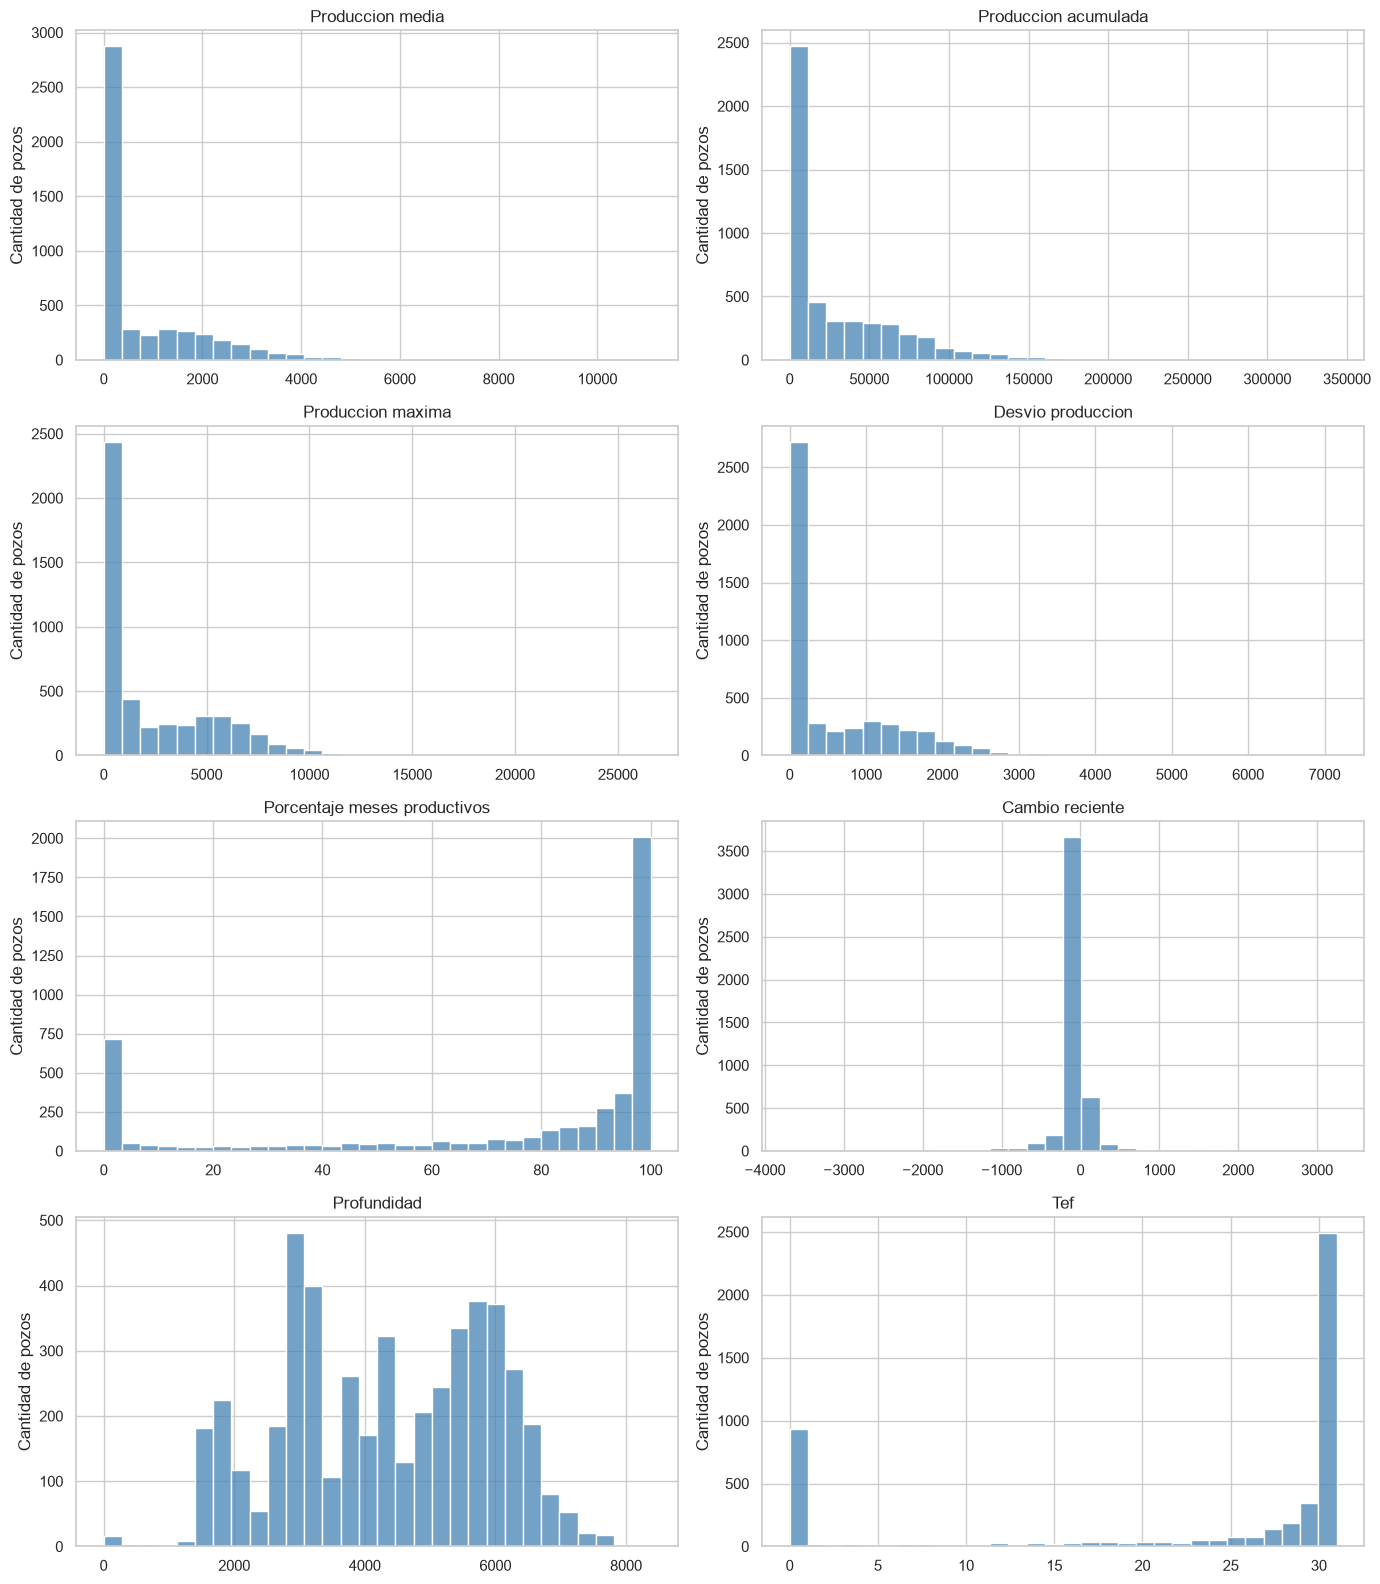

In [6]:
variables_graficar = [
    "produccion_media",
    "produccion_acumulada",
    "produccion_maxima",
    "desvio_produccion",
    "porcentaje_meses_productivos",
    "cambio_reciente",
    "profundidad",
    "tef",
]

fig, ejes = plt.subplots(4, 2, figsize=(14, 16))

for eje, variable in zip(ejes.flat, variables_graficar):
    sns.histplot(
        data=X_clustering,
        x=variable,
        bins=30,
        color="steelblue",
        ax=eje
    )
    eje.set_title(variable.replace("_", " ").capitalize())
    eje.set_xlabel("")
    eje.set_ylabel("Cantidad de pozos")

plt.tight_layout()
plt.show()

## 4. Transformación de variables

La revisión exploratoria mostró que varias variables productivas presentan una distribución asimétrica: muchos pozos tienen valores bajos y un grupo menor concentra valores muy elevados.

En un modelo basado en distancias, estos valores extremos podrían influir demasiado en la formación de los grupos. Por este motivo aplicamos una transformación logarítmica a las variables no negativas seleccionadas.

Utilizamos `log1p`, que calcula:

```text
log(1 + x)

In [7]:
variables_log = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
]

X_transformado = X_clustering.copy()

for variable in variables_log:
    X_transformado[variable] = np.log1p(
        X_transformado[variable]
    )

print("Variables transformadas con log1p:")
print(variables_log)

Variables transformadas con log1p:
['meses_observados', 'produccion_media', 'produccion_mediana', 'produccion_maxima', 'produccion_acumulada', 'desvio_produccion', 'meses_productivos', 'produccion_ultimo_mes', 'produccion_media_3m', 'produccion_media_6m']


La transformación se aplicó a las variables no negativas relacionadas principalmente con la cantidad de meses y el nivel de producción.

La variable `cambio_reciente` se mantiene en su escala original porque contiene valores positivos y negativos. Las variables restantes se conservarán temporalmente sin logaritmo y luego todas serán estandarizadas para que tengan una influencia comparable en el cálculo de distancias.

In [8]:
display(
    X_transformado[variables_log]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",4.190,0.840,1.950,3.610,4.450,4.860,5.510
produccion_media,"4,839.000",4.430,2.880,0.000,1.830,4.550,7.250,9.310
produccion_mediana,"4,839.000",3.860,3.070,0.000,0.000,3.820,6.940,9.190
produccion_maxima,"4,839.000",5.800,3.020,0.000,3.930,6.760,8.440,10.190
produccion_acumulada,"4,839.000",7.910,3.740,0.000,6.350,9.260,10.810,12.750
desvio_produccion,"4,839.000",4.470,2.680,0.000,2.290,4.950,7.000,8.880
meses_productivos,"4,839.000",3.360,1.520,0.000,2.710,3.780,4.510,5.510
produccion_ultimo_mes,"4,839.000",3.310,3.010,0.000,0.000,2.810,6.370,9.270
produccion_media_3m,"4,839.000",3.400,3.020,0.000,0.000,2.980,6.420,9.270
produccion_media_6m,"4,839.000",3.460,3.020,0.000,0.000,3.040,6.460,9.310


## 5. Estandarización de las variables

Después de aplicar las transformaciones logarítmicas, estandarizamos todas las variables seleccionadas utilizando `StandardScaler`.

La estandarización transforma cada variable para que tenga:

- media cercana a 0;
- desvío estándar cercano a 1.

Este paso es necesario porque las variables todavía están expresadas en unidades diferentes. Por ejemplo, `profundidad` está expresada en metros, `porcentaje_meses_productivos` va de 0 a 100 y `tef` tiene valores entre 0 y 31.

Al estandarizar, ninguna variable tendrá una influencia mayor únicamente por utilizar números más grandes.

In [9]:
escalador = StandardScaler()

X_escalado_array = escalador.fit_transform(X_transformado)

X_escalado = pd.DataFrame(
    X_escalado_array,
    columns=X_transformado.columns,
    index=X_transformado.index,
)

display(
    X_escalado.describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",-0.000,1.000,-2.680,-0.690,0.310,0.790,1.570
produccion_media,"4,839.000",-0.000,1.000,-1.540,-0.900,0.040,0.980,1.690
produccion_mediana,"4,839.000",0.000,1.000,-1.260,-1.260,-0.010,1.000,1.740
produccion_maxima,"4,839.000",-0.000,1.000,-1.920,-0.620,0.320,0.870,1.450
produccion_acumulada,"4,839.000",0.000,1.000,-2.120,-0.420,0.360,0.780,1.290
desvio_produccion,"4,839.000",-0.000,1.000,-1.670,-0.810,0.180,0.940,1.650
meses_productivos,"4,839.000",0.000,1.000,-2.210,-0.430,0.280,0.760,1.420
porcentaje_meses_productivos,"4,839.000",-0.000,1.000,-1.930,-0.590,0.570,0.760,0.760
produccion_ultimo_mes,"4,839.000",-0.000,1.000,-1.100,-1.100,-0.160,1.020,1.980
produccion_media_3m,"4,839.000",-0.000,1.000,-1.130,-1.130,-0.140,1.000,1.950


In [10]:
print(
    f"Mayor diferencia absoluta entre medias y 0: "
    f"{X_escalado.mean().abs().max():.10f}"
)

print(
    f"Mayor diferencia absoluta entre desvíos y 1: "
    f"{(X_escalado.std() - 1).abs().max():.10f}"
)

Mayor diferencia absoluta entre medias y 0: 0.0000000000
Mayor diferencia absoluta entre desvíos y 1: 0.0001033432


## 6. Selección de parámetros para DBSCAN

DBSCAN necesita dos parámetros principales:

- `min_samples`: cantidad mínima de observaciones necesarias para considerar que existe una zona densa;
- `eps`: radio máximo de vecindad entre observaciones.

El algoritmo no requiere definir previamente la cantidad de grupos. Esa es una de las razones por las que resulta apropiado para este análisis.

Como estamos trabajando con 16 variables, comenzaremos evaluando valores de `min_samples` relacionados con la cantidad de dimensiones del problema. Primero utilizaremos `min_samples=16` y luego podremos comparar su comportamiento con otras alternativas.

### 6.1. Curva de distancias de vecinos

Para obtener valores candidatos de `eps`, calculamos la distancia de cada pozo a su vecino número `k`, donde `k` coincide con `min_samples`.

Luego ordenamos esas distancias y las representamos gráficamente. El cambio de pendiente de la curva permite identificar un rango razonable de valores para el radio de vecindad.

In [11]:
MIN_SAMPLES_INICIAL = 16

vecinos = NearestNeighbors(
    n_neighbors=MIN_SAMPLES_INICIAL
)

vecinos.fit(X_escalado)

distancias_vecinos, indices_vecinos = vecinos.kneighbors(
    X_escalado
)

distancias_k = np.sort(
    distancias_vecinos[:, -1]
)

print(f"min_samples utilizado: {MIN_SAMPLES_INICIAL}")
print(f"Cantidad de distancias calculadas: {len(distancias_k):,}")
print(f"Distancia mínima: {distancias_k.min():.3f}")
print(f"Distancia mediana: {np.median(distancias_k):.3f}")
print(f"Distancia máxima: {distancias_k.max():.3f}")

min_samples utilizado: 16
Cantidad de distancias calculadas: 4,839
Distancia mínima: 0.134
Distancia mediana: 0.888
Distancia máxima: 8.553


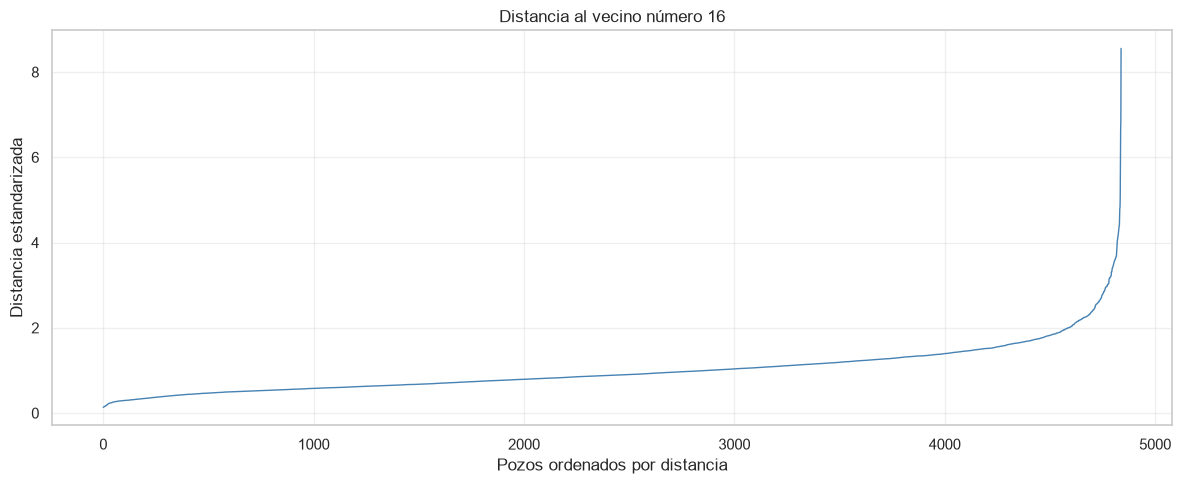

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    np.arange(len(distancias_k)),
    distancias_k,
    color="steelblue",
    linewidth=1
)

ax.set_title(
    f"Distancia al vecino número {MIN_SAMPLES_INICIAL}"
)
ax.set_xlabel("Pozos ordenados por distancia")
ax.set_ylabel("Distancia estandarizada")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.2. Comparación de configuraciones mediante una grilla

La curva de distancias permitió definir un rango inicial de valores para `eps`, pero no alcanza para seleccionar una configuración definitiva.

Por este motivo evaluamos distintas combinaciones de `eps` y `min_samples`. Para cada configuración calculamos:

- cantidad de grupos encontrados;
- porcentaje de pozos considerados ruido;
- tamaño del grupo más grande;
- tamaño del grupo más pequeño;
- silhouette;
- índice de Calinski-Harabasz;
- índice de Davies-Bouldin.

La silhouette, Calinski-Harabasz y Davies-Bouldin son métricas internas. Se calculan sobre los pozos asignados a un grupo y se excluyen los puntos marcados como ruido (`-1`).

Estas métricas no se interpretan de manera aislada. Una configuración puede obtener buenos valores internos dejando fuera una proporción excesiva de pozos. Por eso también revisamos el porcentaje de ruido, el tamaño de los grupos y la utilidad de la segmentación.

In [13]:
def metricas_dbscan(X, etiquetas):
    etiquetas = np.asarray(etiquetas)

    mascara_no_ruido = etiquetas != -1
    X_sin_ruido = X[mascara_no_ruido]
    etiquetas_sin_ruido = etiquetas[mascara_no_ruido]

    grupos = np.unique(etiquetas_sin_ruido)
    cantidad_grupos = len(grupos)

    porcentaje_ruido = 100 * np.mean(~mascara_no_ruido)
    porcentaje_asignado = 100 - porcentaje_ruido

    if cantidad_grupos >= 2:
        silueta = silhouette_score(
            X_sin_ruido,
            etiquetas_sin_ruido,
        )

        calinski = calinski_harabasz_score(
            X_sin_ruido,
            etiquetas_sin_ruido,
        )

        davies = davies_bouldin_score(
            X_sin_ruido,
            etiquetas_sin_ruido,
        )
    else:
        silueta = np.nan
        calinski = np.nan
        davies = np.nan

    tamanios = pd.Series(
        etiquetas_sin_ruido
    ).value_counts()

    if tamanios.empty:
        grupo_mayor = 0
        grupo_menor = 0
    else:
        grupo_mayor = int(tamanios.max())
        grupo_menor = int(tamanios.min())

    return {
        "grupos": cantidad_grupos,
        "ruido_%": porcentaje_ruido,
        "asignados_%": porcentaje_asignado,
        "grupo_mayor": grupo_mayor,
        "grupo_menor": grupo_menor,
        "silueta": silueta,
        "calinski_harabasz": calinski,
        "davies_bouldin": davies,
    }

Para la primera búsqueda utilizamos valores de `eps` cercanos al rango sugerido por la curva de vecinos. También comparamos distintos valores de `min_samples` para verificar si la estructura encontrada se mantiene o cambia demasiado.

In [14]:
def grilla_dbscan(
    X,
    eps_valores,
    min_samples_valores,
):
    filas = []

    for min_samples in min_samples_valores:
        for eps in eps_valores:
            etiquetas = DBSCAN(
                eps=eps,
                min_samples=min_samples,
            ).fit_predict(X)

            fila = {
                "eps": round(float(eps), 2),
                "min_samples": min_samples,
            }

            fila.update(
                metricas_dbscan(X, etiquetas)
            )

            filas.append(fila)

    return pd.DataFrame(filas)

In [15]:
eps_valores = np.arange(0.8, 2.01, 0.1)
min_samples_valores = [8, 12, 16, 24]

grilla_resultados = grilla_dbscan(
    X_escalado.to_numpy(),
    eps_valores,
    min_samples_valores,
)

display(
    grilla_resultados.sort_values(
        ["silueta", "ruido_%"],
        ascending=[False, True],
    ).head(15)
)

,eps,min_samples,grupos,ruido_%,asignados_%,grupo_mayor,grupo_menor,silueta,calinski_harabasz,davies_bouldin
39,0.800,24,10,50.754,49.246,1202,44,0.465,"1,899.496",0.805
10,1.800,8,2,1.695,98.305,4746,11,0.398,42.790,0.603
11,1.900,8,2,1.550,98.450,4753,11,0.397,42.714,0.603
12,2.000,8,2,1.157,98.843,4772,11,0.394,42.208,0.606
43,1.200,24,4,17.772,82.228,3082,233,0.272,"1,104.766",1.136
9,1.700,8,3,2.273,97.727,4712,6,0.268,29.799,0.637
8,1.600,8,3,3.100,96.900,4670,8,0.268,32.762,0.656
40,0.900,24,8,40.897,59.103,2143,26,0.257,647.265,0.758
42,1.100,24,6,25.294,74.706,2844,33,0.230,678.356,1.050
41,1.000,24,10,31.473,68.527,2508,30,0.187,444.830,0.883


## 7. Evaluación inicial de las configuraciones

La grilla permitió comparar distintas configuraciones de DBSCAN mediante métricas internas y medidas descriptivas.

En esta etapa no seleccionamos automáticamente la configuración con la mayor silhouette. Consideramos conjuntamente:

- calidad de separación y compactación;
- porcentaje de ruido;
- porcentaje de pozos asignados;
- tamaño de los grupos;
- presencia de un grupo dominante;
- utilidad de la segmentación para interpretar perfiles de pozos.

Una configuración con buenas métricas internas, pero con demasiado ruido o grupos poco útiles, no necesariamente resulta adecuada para nuestro objetivo.

### 7.1. Revisión de tamaños de los grupos

Además de la silueta y del porcentaje de ruido, analizamos cuántos pozos quedan en cada grupo.

Esta revisión permite detectar configuraciones que generan un único grupo dominante o muchos grupos demasiado pequeños.

Para esta comparación informamos:

- cantidad de pozos por grupo;
- porcentaje de pozos por grupo;
- cantidad de pozos considerados ruido.

In [16]:
def resumen_tamanios(etiquetas):
    etiquetas = pd.Series(etiquetas, name="cluster")

    tamanios = (
        etiquetas.value_counts()
        .sort_index()
        .rename("pozos")
        .to_frame()
    )

    tamanios["porcentaje"] = (
        100 * tamanios["pozos"] / len(etiquetas)
    ).round(2)

    return tamanios

In [17]:
configuraciones_candidatas = [
    {"eps": 0.8, "min_samples": 24},
    {"eps": 1.2, "min_samples": 24},
    {"eps": 1.8, "min_samples": 8},
    {"eps": 1.9, "min_samples": 8},
]

resultados_candidatos = {}

for configuracion in configuraciones_candidatas:
    modelo = DBSCAN(
        eps=configuracion["eps"],
        min_samples=configuracion["min_samples"],
    )

    etiquetas = modelo.fit_predict(X_escalado)

    clave = (
        f"eps={configuracion['eps']}, "
        f"min_samples={configuracion['min_samples']}"
    )

    resultados_candidatos[clave] = etiquetas

    print(f"\n{clave}")
    display(resumen_tamanios(etiquetas))


eps=0.8, min_samples=24


,pozos,porcentaje
cluster,,
-1,2456,50.750
0,180,3.720
1,44,0.910
2,290,5.990
3,94,1.940
4,53,1.100
5,236,4.880
6,52,1.070
7,155,3.200



eps=1.2, min_samples=24


,pozos,porcentaje
cluster,,
-1,860,17.770
0,3082,63.690
1,336,6.940
2,328,6.780
3,233,4.820



eps=1.8, min_samples=8

,pozos,porcentaje
cluster,,
-1,82,1.690
0,4746,98.080
1,11,0.230



eps=1.9, min_samples=8


,pozos,porcentaje
cluster,,
-1,75,1.550
0,4753,98.220
1,11,0.230


### 7.2. Selección de configuraciones candidatas

A partir de la comparación realizada, descartamos las configuraciones que presentan una de estas características:

- porcentaje de ruido excesivo;
- un único grupo que concentra casi todos los pozos;
- grupos demasiado pequeños;
- segmentación difícil de interpretar.

La configuración `eps=0,8` y `min_samples=24` obtuvo los mejores valores de silhouette y Calinski-Harabasz, pero dejó como ruido al 50,75 % de los pozos. Por este motivo no la consideramos adecuada como modelo principal.

Las configuraciones con `min_samples=8` asignaron más del 98 % de los pozos a un único grupo. Aunque tienen poco ruido, generan una segmentación muy débil.

La configuración `eps=1,2` y `min_samples=24` generó cuatro grupos, asignó el 82,23 % de los pozos y produjo un grupo menor de 233 observaciones. Por estas características, se selecciona como candidata principal para el análisis detallado.

Esta decisión todavía no es definitiva. En la siguiente sección analizaremos las características productivas y físicas de los grupos para verificar si la segmentación es interpretable.

### 7.3. Análisis del modelo candidato

Aplicamos la configuración candidata principal:

- `eps=1,2`;
- `min_samples=24`.

A partir de las etiquetas obtenidas analizamos las características productivas y físicas de cada grupo.

También conservamos la etiqueta `-1`, que representa los pozos considerados ruido por DBSCAN. Estos pozos no se interpretan como un grupo productivo, sino como perfiles que no pertenecen claramente a ninguna zona densa.

In [18]:
EPS_CANDIDATO = 1.2
MIN_SAMPLES_CANDIDATO = 24

modelo_dbscan_candidato = DBSCAN(
    eps=EPS_CANDIDATO,
    min_samples=MIN_SAMPLES_CANDIDATO,
)

etiquetas_candidato = modelo_dbscan_candidato.fit_predict(
    X_escalado
)

perfiles_candidato = perfiles_pozos.copy()
perfiles_candidato["cluster"] = etiquetas_candidato

print(f"eps utilizado: {EPS_CANDIDATO}")
print(f"min_samples utilizado: {MIN_SAMPLES_CANDIDATO}")
print(
    f"Pozos asignados a grupos: "
    f"{(etiquetas_candidato != -1).sum():,}"
)
print(
    f"Pozos considerados ruido: "
    f"{(etiquetas_candidato == -1).sum():,}"
)

display(
    perfiles_candidato["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("pozos")
)

eps utilizado: 1.2
min_samples utilizado: 24
Pozos asignados a grupos: 3,979
Pozos considerados ruido: 860


,pozos
cluster,
-1,860
0,3082
1,336
2,328
3,233


### 7.4. Resumen estadístico de los grupos

Ahora comparamos las principales variables numéricas entre los grupos obtenidos.

El objetivo es identificar diferencias en:

- nivel de producción;
- producción acumulada;
- continuidad;
- antigüedad;
- variabilidad;
- comportamiento reciente.

El valor `-1` corresponde a los pozos considerados ruido. Lo incluimos en la tabla como referencia, pero no lo interpretamos como un grupo productivo.

In [19]:
variables_resumen_clusters = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "porcentaje_meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
    "cambio_reciente",
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "tef",
]

resumen_clusters = (
    perfiles_candidato
    .groupby("cluster")[variables_resumen_clusters]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(resumen_clusters)

meses_observados                 produccion_media                    \
                   count    mean  median            count      mean  median   
cluster                                                                       
-1                   860  83.060  61.000              860   837.040  57.490   
 0                  3082  78.970  68.000             3082 1,053.110 507.080   
 1                   336 142.260 137.500              336    92.190  29.140   
 2                   328 100.450 108.500              328     0.010   0.000   
 3                   233 106.190 108.000              233     0.010   0.000   

        produccion_mediana                 produccion_maxima            \
                     count    mean  median             count      mean   
cluster                                                                  
-1                     860 723.240   0.240               860 2,367.070   
 0                    3082 891.950 391.060              3082 3,050.930   
 1                     336  47.890   0.740               336   718.440   
 2                     328   0.000   0.000               328     0.780   
 3                     233   0.000   0.000               233     0.460   

                  produccion_acumulada                        \
           median                count       mean     median   
cluster                                                        
-1        497.800                  860 22,165.820  5,076.300   
 0      2,149.230                 3082 37,640.460 24,210.830   
 1        365.480                  336 10,849.390  4,311.830   
 2          0.000                  328      1.110      0.000   
 3          0.000                  233      0.880      0.000   

        desvio_produccion                 meses_productivos                \
                    count    mean  median             count   mean median   
cluster                                                                     
-1                    860 670.200  92.850               860 34.940 22.000   
 0                   3082 728.840 430.280              3082 70.960 61.000   
 1                    336 130.750  57.010               336 68.710 76.500   
 2                    328   0.080   0.000               328  0.600  0.000   
 3                    233   0.050   0.000               233  0.270  0.000   

        porcentaje_meses_productivos               produccion_ultimo_mes  \
                               count   mean median                 count   
cluster                                                                    
-1                               860 53.100 51.920                   860   
 0                              3082 92.460 98.250                  3082   
 1                               336 48.850 52.060                   336   
 2                               328  0.470  0.000                   328   
 3                               233  0.230  0.000                   233   

                        produccion_media_3m                  \
           mean  median               count    mean  median   
cluster                                                       
-1      594.830   0.000                 860 650.500   0.650   
 0      622.840 200.120                3082 651.460 229.520   
 1        0.040   0.000                 336   0.080   0.000   
 2        0.030   0.000                 328   0.010   0.000   
 3        0.000   0.000                 233   0.000   0.000   

        produccion_media_6m                 cambio_reciente                 \
                      count    mean  median           count    mean median   
cluster                                                                      
-1                      860 681.070   2.880             860 -30.570  0.000   
 0                     3082 681.460 243.540            3082 -30.000  0.000   
 1                      336   0.490   0.000             336  -0.410  0.000   
 2                      328   0.010   0.000             328   0.000  0

In [20]:
resumen_productivo_clusters = (
    perfiles_candidato
    .groupby("cluster")
    .agg(
        pozos=("idpozo", "count"),
        produccion_media=("produccion_media", "mean"),
        produccion_mediana=("produccion_mediana", "mean"),
        produccion_acumulada=("produccion_acumulada", "mean"),
        desvio_produccion=("desvio_produccion", "mean"),
        porcentaje_meses_productivos=(
            "porcentaje_meses_productivos",
            "mean",
        ),
        produccion_media_3m=("produccion_media_3m", "mean"),
        produccion_media_6m=("produccion_media_6m", "mean"),
        meses_desde_inicio=("meses_desde_inicio", "mean"),
    )
    .round(2)
)

display(resumen_productivo_clusters)

,pozos,produccion_media,produccion_mediana,produccion_acumulada,desvio_produccion,porcentaje_meses_productivos,produccion_media_3m,produccion_media_6m,meses_desde_inicio
cluster,,,,,,,,,
-1,860,837.040,723.240,"22,165.820",670.200,53.100,650.500,681.070,84.980
0,3082,"1,053.110",891.950,"37,640.460",728.840,92.460,651.460,681.460,78.890
1,336,92.190,47.890,"10,849.390",130.750,48.850,0.080,0.490,146.490
2,328,0.010,0.000,1.110,0.080,0.470,0.010,0.010,100.050
3,233,0.010,0.000,0.880,0.050,0.230,0.000,0.000,105.690


### 7.5. Comparación visual de los perfiles

La tabla resumen permite observar las diferencias promedio entre los clusters. Para complementar este análisis, visualizamos algunas variables productivas mediante boxplots.

Las variables seleccionadas representan el nivel productivo, la continuidad, la producción acumulada y el comportamiento reciente.

Se mantiene el ruido (`-1`) en los gráficos para observar cómo se diferencia de los grupos asignados.

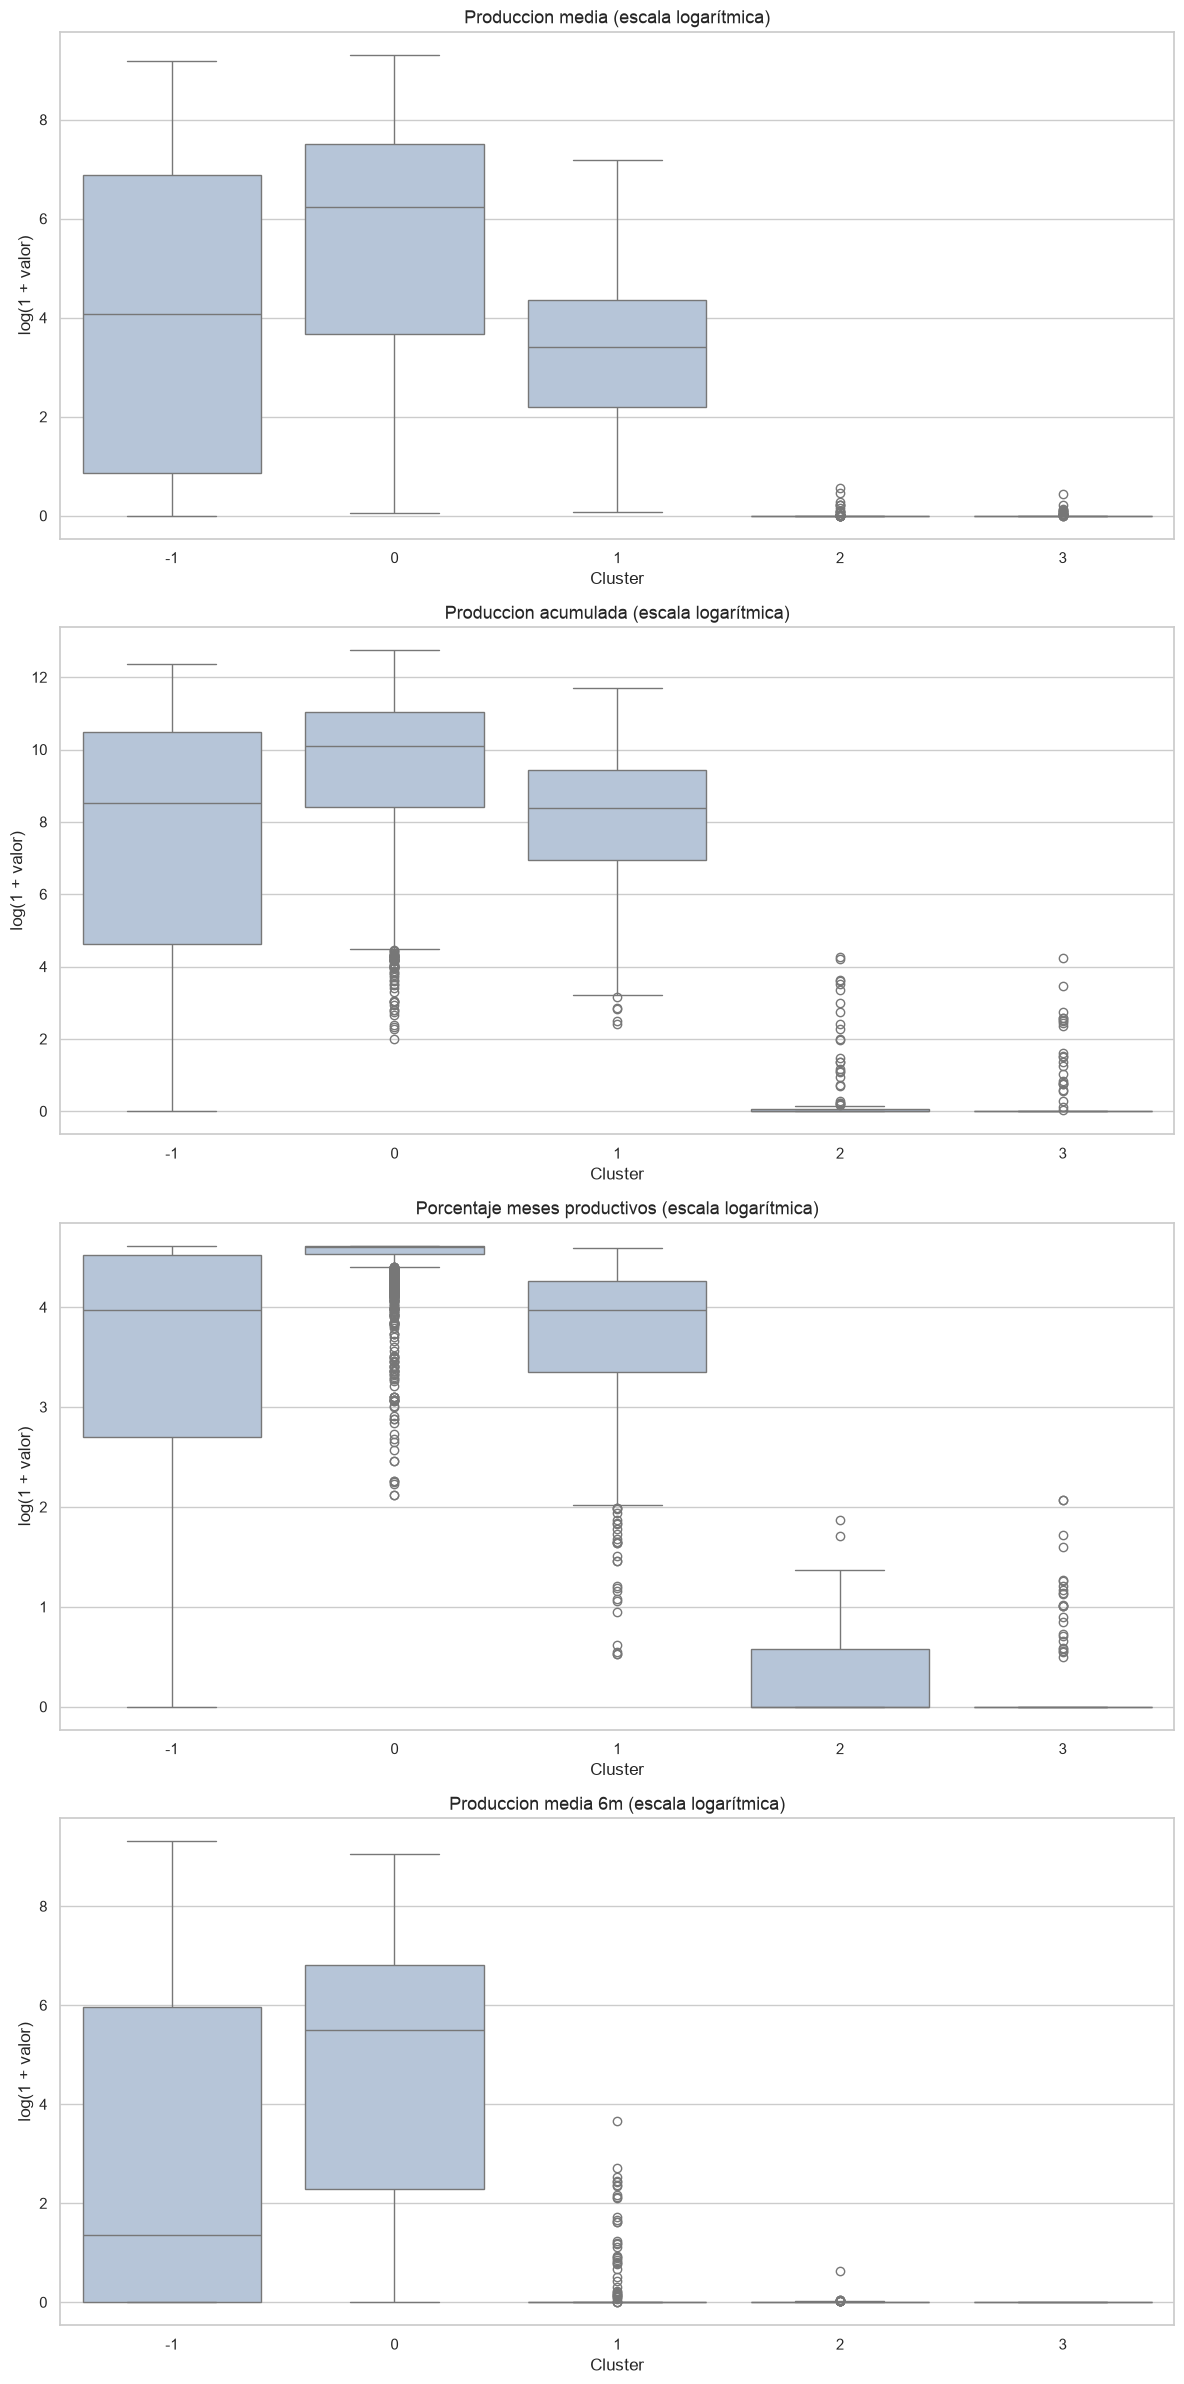

In [21]:
variables_graficos_clusters = [
    "produccion_media",
    "produccion_acumulada",
    "porcentaje_meses_productivos",
    "produccion_media_6m",
]

perfiles_graficos = perfiles_candidato.copy()

for variable in variables_graficos_clusters:
    perfiles_graficos[f"{variable}_log1p"] = np.log1p(
        perfiles_graficos[variable]
    )

fig, ejes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(12, 24)
)

for eje, variable in zip(ejes, variables_graficos_clusters):
    columna_transformada = f"{variable}_log1p"

    sns.boxplot(
        data=perfiles_graficos,
        x="cluster",
        y=columna_transformada,
        color="lightsteelblue",
        ax=eje,
    )

    eje.set_title(
        f"{variable.replace('_', ' ').capitalize()} "
        "(escala logarítmica)",
        fontsize=13,
    )
    eje.set_xlabel("Cluster")
    eje.set_ylabel("log(1 + valor)")

plt.tight_layout()
plt.show()

Los gráficos muestran diferencias claras entre los perfiles obtenidos.

El cluster 0 concentra los pozos con mayor nivel de producción, mayor producción acumulada y una alta proporción de meses productivos.

El cluster 1 presenta una producción histórica menor y un comportamiento reciente prácticamente nulo, aunque sus pozos cuentan con una trayectoria relativamente extensa.

Los clusters 2 y 3 se caracterizan por niveles de producción prácticamente nulos y una proporción muy baja de meses productivos. La diferencia entre ambos deberá analizarse con variables físicas, operativas y categóricas.

Los pozos clasificados como ruido (`-1`) presentan una mayor dispersión y no forman una zona densa suficientemente homogénea. Por ese motivo no se interpretan como un grupo productivo único.

## 8. Análisis de componentes principales

En esta sección utilizamos PCA para estudiar la estructura de los perfiles y facilitar su visualización.

PCA no utiliza las etiquetas generadas por DBSCAN ni las variables categóricas. Por lo tanto, las componentes se obtienen únicamente a partir de las variables numéricas transformadas y estandarizadas.

Por ahora, PCA se utilizará como herramienta de análisis y visualización. Más adelante evaluaremos si conviene comparar un segundo DBSCAN utilizando las componentes principales.

### 8.1. Varianza explicada

PCA transforma las variables originales en componentes principales ordenadas según la cantidad de variabilidad que explican.

La primera componente concentra la mayor variación posible, la segunda concentra la mayor parte de la variación restante y así sucesivamente.

Analizamos la varianza explicada para saber cuánta información se conserva al utilizar menos dimensiones que las 16 variables originales. Este análisis no define por sí solo el modelo final de clustering.

In [22]:
pca_completo = PCA()

X_pca_completo = pca_completo.fit_transform(
    X_escalado
)

varianza_explicada = pd.DataFrame(
    {
        "componente": np.arange(
            1,
            len(pca_completo.explained_variance_ratio_) + 1
        ),
        "varianza_explicada": (
            pca_completo.explained_variance_ratio_
        ),
        "varianza_acumulada": (
            pca_completo.explained_variance_ratio_.cumsum()
        ),
    }
)

display(
    varianza_explicada.round(4)
)

,componente,varianza_explicada,varianza_acumulada
0,1,0.582,0.582
1,2,0.150,0.732
2,3,0.067,0.799
3,4,0.063,0.863
4,5,0.051,0.914
5,6,0.034,0.948
6,7,0.022,0.970
7,8,0.012,0.982
8,9,0.007,0.989
9,10,0.005,0.995


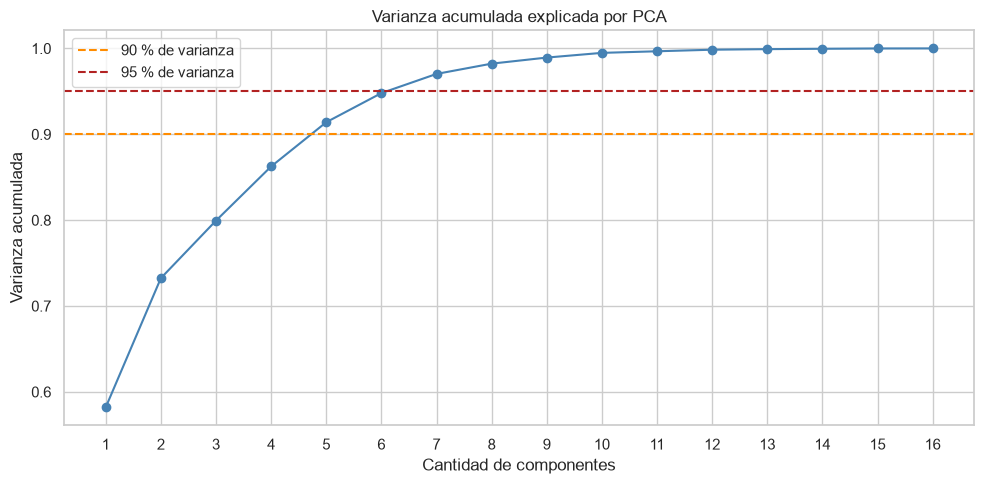

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    varianza_explicada["componente"],
    varianza_explicada["varianza_acumulada"],
    marker="o",
    color="steelblue",
)

ax.axhline(
    0.90,
    color="darkorange",
    linestyle="--",
    label="90 % de varianza",
)

ax.axhline(
    0.95,
    color="firebrick",
    linestyle="--",
    label="95 % de varianza",
)

ax.set_title("Varianza acumulada explicada por PCA")
ax.set_xlabel("Cantidad de componentes")
ax.set_ylabel("Varianza acumulada")
ax.set_xticks(varianza_explicada["componente"])
ax.legend()

plt.tight_layout()
plt.show()

### 8.2. Interpretación de las componentes principales

Para interpretar las componentes observamos sus cargas. Cada carga indica cuánto se relaciona una variable original con una componente principal.

Las variables con valores absolutos más altos son las que tienen mayor influencia en la componente. El signo puede ser positivo o negativo y no debe interpretarse como una valoración positiva o negativa: lo importante es la magnitud de la carga y la relación entre las variables.

Analizamos especialmente las primeras siete componentes, ya que en conjunto explican aproximadamente el 97 % de la variabilidad de los perfiles.

In [24]:
cargas_pca = pd.DataFrame(
    pca_completo.components_.T,
    index=X_escalado.columns,
    columns=[
        f"PC{i}"
        for i in range(1, X_escalado.shape[1] + 1)
    ],
)

display(
    cargas_pca.iloc[:, :7].round(3)
)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
meses_observados,-0.208,0.434,-0.031,0.079,0.068,0.385,0.022
produccion_media,0.320,0.032,-0.120,0.094,-0.060,0.051,-0.065
produccion_mediana,0.313,-0.022,-0.040,0.013,-0.005,0.007,-0.079
produccion_maxima,0.301,0.166,-0.167,0.132,-0.087,0.058,-0.028
produccion_acumulada,0.290,0.261,-0.145,0.111,-0.062,-0.029,0.025
desvio_produccion,0.311,0.082,-0.159,0.134,-0.087,0.093,-0.045
meses_productivos,0.121,0.567,-0.019,0.011,0.055,-0.268,0.245
porcentaje_meses_productivos,0.255,0.292,0.071,-0.099,0.080,-0.445,0.146
produccion_ultimo_mes,0.304,-0.087,0.177,0.027,0.099,0.191,-0.266
produccion_media_3m,0.310,-0.094,0.108,0.018,0.073,0.164,-0.261


In [25]:
for componente in cargas_pca.columns[:7]:
    principales = (
        cargas_pca[componente]
        .abs()
        .sort_values(ascending=False)
        .head(5)
        .index
    )

    tabla_componentes = (
        cargas_pca.loc[principales, [componente]]
        .sort_values(
            by=componente,
            key=lambda columna: columna.abs(),
            ascending=False,
        )
        .round(3)
    )

    print(f"\n{componente}:")
    display(tabla_componentes)


PC1:


,PC1
produccion_media,0.320
produccion_media_6m,0.313
produccion_mediana,0.313
desvio_produccion,0.311
produccion_media_3m,0.310



PC2:


,PC2
meses_productivos,0.567
meses_observados,0.434
meses_desde_inicio,0.418
porcentaje_meses_productivos,0.292
produccion_acumulada,0.261



PC3:


,PC3
cambio_reciente,0.643
tef,0.638
produccion_ultimo_mes,0.177
produccion_maxima,-0.167
cota,-0.163


... (4 outputs left out)


PC6:


,PC6
meses_desde_inicio,0.536
porcentaje_meses_productivos,-0.445
profundidad,0.403
meses_observados,0.385
meses_productivos,-0.268



PC7:


,PC7
profundidad,0.797
produccion_ultimo_mes,-0.266
produccion_media_3m,-0.261
meses_productivos,0.245
produccion_media_6m,-0.232


#### Lectura de las primeras componentes

La primera componente `(PC1)` concentra principalmente variables relacionadas con el nivel de producción histórica y reciente. Por este motivo, puede interpretarse como un eje de intensidad productiva.

La segunda componente `(PC2)` está asociada con la continuidad y la antigüedad del historial del pozo, debido a la importancia de los meses observados, los meses productivos y los meses desde el inicio.

La tercera componente `(PC3)` se relaciona principalmente con el cambio reciente y el indicador `tef`, por lo que representa diferencias en la evolución reciente y en esa característica física.

Las componentes cuarta `(PC4)` y quinta `(PC5)` están influenciadas principalmente por la cota y por algunas variables relacionadas con el cambio reciente y `tef`.

La sexta componente `(PC6)` combina información sobre antigüedad, profundidad y continuidad productiva. Finalmente, la séptima `(PC7)` está dominada por la profundidad.

Estas interpretaciones son descriptivas y no indican relaciones causales. PCA resume la estructura estadística de los datos, pero no demuestra que una variable provoque el comportamiento de otra.

### 8.3. Visualización de los pozos y de los grupos obtenidos

En esta sección representamos cada pozo utilizando sus coordenadas en las dos primeras componentes principales.

Los colores corresponden a las etiquetas generadas previamente por DBSCAN con la configuración seleccionada:

- `eps = 1,2`;
- `min_samples = 24`.

Es importante aclarar que PCA no vuelve a formar los grupos. Las etiquetas ya fueron obtenidas por DBSCAN utilizando las 16 variables numéricas transformadas y estandarizadas. PCA solamente permite representar esos resultados en un plano de dos dimensiones.

La etiqueta `-1` corresponde a los pozos considerados ruido por DBSCAN. Las etiquetas `0`, `1`, `2` y `3` corresponden a los cuatro grupos encontrados.

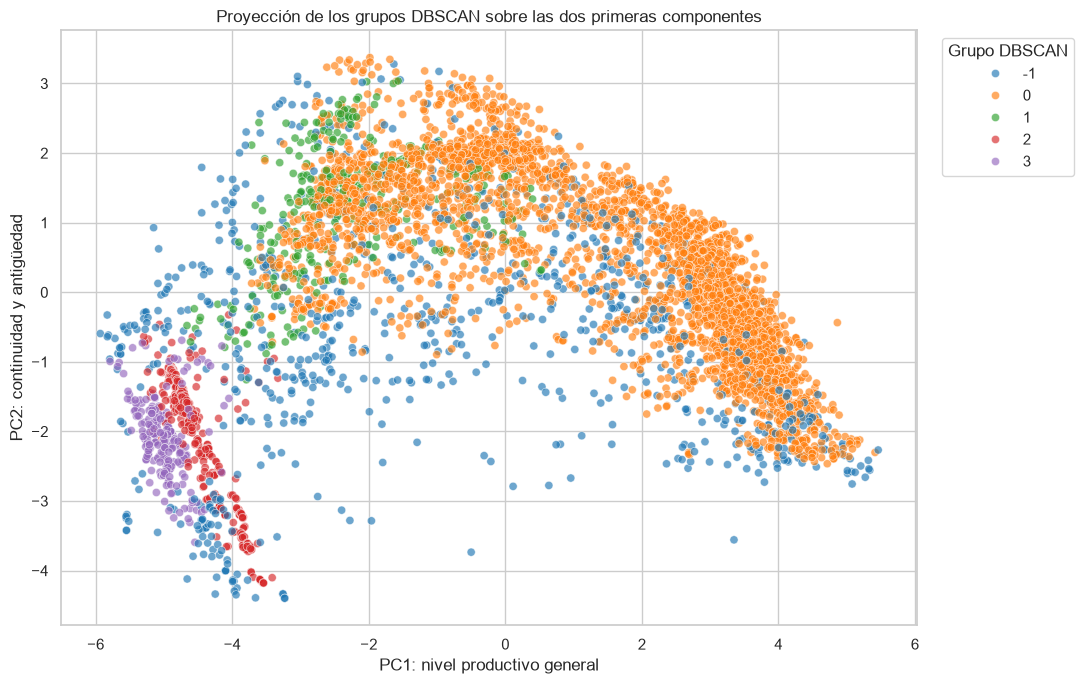

In [26]:
pca_2d = pd.DataFrame(
    X_pca_completo[:, :2],
    columns=["PC1", "PC2"],
    index=perfiles_pozos.index,
)

pca_2d["cluster"] = etiquetas_candidato

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_2d,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.65,
    s=35,
)

plt.title(
    "Proyección de los grupos DBSCAN sobre las dos primeras componentes"
)
plt.xlabel("PC1: nivel productivo general")
plt.ylabel("PC2: continuidad y antigüedad")

plt.legend(
    title="Grupo DBSCAN",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

El gráfico permite observar cómo se proyectan los grupos en el espacio definido por PC1 y PC2. La superposición de colores no implica necesariamente un error del modelo, porque estas dos componentes no contienen toda la información utilizada por DBSCAN. En conjunto explican aproximadamente el 73,2 % de la variabilidad, mientras que el resto se encuentra distribuido en las componentes posteriores.

En la visualización se observa que el grupo 0 concentra la mayor cantidad de pozos y ocupa gran parte del espacio proyectado. El ruido, representado con la etiqueta `-1`, aparece distribuido en distintas zonas, lo cual es esperable porque no constituye un grupo homogéneo.

Los grupos 1, 2 y 3 aparecen más concentrados hacia la zona de menor continuidad y menor nivel productivo, aunque también presentan cierta superposición. Esto indica que las diferencias entre los grupos no pueden explicarse únicamente mediante PC1 y PC2, sino que también dependen de las componentes restantes.

Por lo tanto, esta figura se utiliza como apoyo visual y no como único criterio para validar la calidad del agrupamiento. La evaluación principal continúa basándose en las métricas calculadas sobre las 16 variables utilizadas por DBSCAN.

## 9. DBSCAN utilizando componentes principales

En esta sección evaluamos si las primeras componentes principales pueden utilizarse como representación alternativa para aplicar DBSCAN.

Las siete primeras componentes conservan aproximadamente el 97 % de la variabilidad de las 16 variables originales. Sin embargo, al reducir la dimensión también pueden modificarse las distancias entre los pozos y la estructura de densidad.

Por este motivo, no reutilizamos directamente los parámetros del modelo original. Primero analizamos nuevamente las distancias en el espacio PCA y luego comparamos distintas configuraciones de DBSCAN.

### 9.1. Preparación de las componentes principales

Seleccionamos las siete primeras componentes principales para construir una representación reducida de los perfiles.

Cada fila continúa representando un pozo, pero ahora las variables de entrada son `PC1` a `PC7`. Estas componentes no corresponden directamente a variables originales, sino a combinaciones lineales de ellas.

La tabla siguiente permite verificar que se conservaron los 4.839 pozos y que la nueva representación tiene siete dimensiones.

In [27]:
cantidad_componentes = 7

X_pca_7 = pd.DataFrame(
    X_pca_completo[:, :cantidad_componentes],
    columns=[
        f"PC{i}"
        for i in range(1, cantidad_componentes + 1)
    ],
    index=X_escalado.index,
)

print(f"Componentes utilizadas: {cantidad_componentes}")
print(f"Perfiles utilizados: {X_pca_7.shape[0]:,}")

display(X_pca_7.head())

Componentes utilizadas: 7
Perfiles utilizados: 4,839


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-1.539,3.052,-1.427,0.963,-0.241,0.285,-0.697
1,-4.084,1.177,-1.248,0.516,-0.861,1.706,-0.564
2,-0.813,2.992,0.459,-0.044,0.779,1.206,0.136
3,-2.211,3.031,0.497,-0.744,0.182,0.824,0.092
4,-2.581,2.754,0.645,0.098,1.364,0.500,0.517


### 9.2. Curva de distancias en el espacio PCA

Para orientar la selección de `eps`, calculamos la distancia al vecino número 16 de cada pozo.

Utilizamos 16 como referencia inicial porque fue el valor definido al comenzar el análisis con las variables numéricas originales.

La curva no determina por sí sola el valor final de `eps`. Solamente permite identificar un rango de distancias que luego debe evaluarse mediante una grilla de configuraciones.

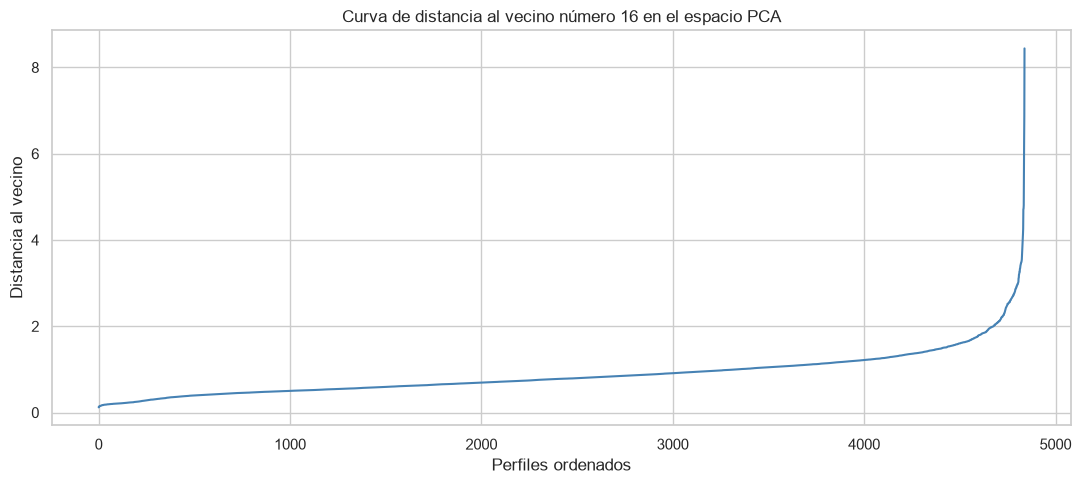

In [28]:
MIN_SAMPLES_PCA_REFERENCIA = 16

vecinos_pca = NearestNeighbors(
    n_neighbors=MIN_SAMPLES_PCA_REFERENCIA
)

vecinos_pca.fit(X_pca_7)

distancias_pca, _ = vecinos_pca.kneighbors(
    X_pca_7
)

distancias_k_pca = np.sort(
    distancias_pca[:, -1]
)

plt.figure(figsize=(11, 5))

plt.plot(
    distancias_k_pca,
    color="steelblue",
)

plt.title(
    "Curva de distancia al vecino número "
    f"{MIN_SAMPLES_PCA_REFERENCIA} en el espacio PCA"
)

plt.xlabel("Perfiles ordenados")
plt.ylabel("Distancia al vecino")

plt.tight_layout()
plt.show()

La curva presenta un crecimiento gradual durante la mayor parte de los perfiles y aumenta con mayor rapidez hacia el extremo final. Esto sugiere que los valores de `eps` más cercanos a esa zona pueden incorporar una gran cantidad de observaciones a los grupos.

Por este motivo, no seleccionamos un valor único a partir del gráfico. Evaluamos distintos valores de `eps` y de `min_samples` mediante una grilla, utilizando las mismas métricas que en el modelo original.

### 9.3. Comparación de configuraciones mediante una grilla

A partir de la curva de distancias, concentramos la búsqueda en valores de `eps` cercanos al cambio de pendiente observado, aproximadamente entre 1,8 y 2,4.

No elegimos automáticamente un valor único a partir de la curva. El punto de inflexión solamente orienta la búsqueda; la decisión final también considera la cantidad de grupos, el porcentaje de ruido, el tamaño de los grupos y las métricas internas.

Utilizamos los mismos valores de `min_samples` evaluados en el modelo original para poder comparar las representaciones de manera consistente.

In [29]:
eps_valores_pca = np.arange(
    1.8,
    2.41,
    0.1
)

min_samples_valores_pca = [
    8,
    12,
    16,
    24,
]

grilla_resultados_pca = grilla_dbscan(
    X_pca_7.to_numpy(),
    eps_valores_pca,
    min_samples_valores_pca,
)

resultados_pca_ordenados = (
    grilla_resultados_pca
    .sort_values(
        ["silueta", "ruido_%"],
        ascending=[False, True],
    )
)

display(
    resultados_pca_ordenados
)

,eps,min_samples,grupos,ruido_%,asignados_%,grupo_mayor,grupo_menor,silueta,calinski_harabasz,davies_bouldin
19,2.300,16,2,0.661,99.339,4791,16,0.422,69.082,0.648
20,2.400,16,2,0.599,99.401,4794,16,0.422,68.994,0.648
12,2.300,12,2,0.517,99.483,4799,15,0.405,58.296,0.662
13,2.400,12,2,0.475,99.525,4801,15,0.405,58.167,0.662
8,1.900,12,2,1.364,98.636,4761,12,0.403,46.959,0.608
0,1.800,8,2,1.240,98.760,4767,12,0.402,46.655,0.609
1,1.900,8,2,1.013,98.987,4778,12,0.401,46.596,0.609
9,2.000,12,2,1.095,98.905,4773,13,0.396,49.277,0.632
10,2.100,12,2,0.785,99.215,4788,13,0.395,49.004,0.633
11,2.200,12,2,0.620,99.380,4796,13,0.393,48.609,0.635


Las configuraciones con mejores valores de silhouette se encuentran principalmente entre `eps=1,8` y `eps=2,4`. Sin embargo, todas producen solamente dos grupos y concentran más del 98 % de los pozos en un único grupo.

Por ejemplo, con `eps=2,3` y `min_samples=16`, se obtiene una silhouette de 0,422 y apenas 0,661 % de ruido. No obstante, el grupo mayor contiene 4.791 pozos, mientras que el grupo menor contiene solamente 16.

Esto muestra que un valor favorable de silhouette y un bajo porcentaje de ruido no garantizan una segmentación útil. En este caso, las componentes principales generan una separación entre un grupo muy grande y un conjunto reducido de perfiles, pero no logran formar varios grupos productivos equilibrados.

Por lo tanto, no seleccionamos ninguna de estas configuraciones como modelo final sobre PCA.

### 9.4. Conclusión de la comparación con PCA

La aplicación de DBSCAN sobre las siete primeras componentes principales no mejora el agrupamiento obtenido con las 16 variables originales.

Aunque el modelo sobre PCA presenta poco ruido y valores de silhouette cercanos a 0,422, genera una segmentación muy desbalanceada: casi todos los pozos quedan en un único grupo y el segundo grupo contiene muy pocas observaciones.

En cambio, el modelo original con `eps=1,2` y `min_samples=24` produce cuatro grupos y un 17,77 % de ruido, pero permite distinguir perfiles productivos con tamaños más útiles para el análisis.

Por este motivo, mantenemos como modelo principal el DBSCAN aplicado sobre las 16 variables numéricas transformadas y escaladas. PCA queda como herramienta complementaria para estudiar la estructura de los datos y visualizar los grupos.

## 10. Evaluación de la estabilidad del modelo

Antes de interpretar definitivamente los grupos, analizamos si la configuración seleccionada mantiene resultados similares cuando se trabaja con distintas muestras de los datos.

Utilizamos nuevamente el modelo original:

- `eps = 1,2`;
- `min_samples = 24`;
- 16 variables numéricas transformadas y escaladas.

En cada repetición seleccionamos aleatoriamente el 80 % de los pozos, aplicamos DBSCAN y comparamos las etiquetas obtenidas con las etiquetas del modelo completo.

La comparación se realiza mediante el índice ARI (Adjusted Rand Index), que permite comparar agrupamientos aunque los números de los clusters cambien entre ejecuciones.

In [30]:
RANDOM_STATE = 42
PROPORCION_MUESTRA = 0.80
REPETICIONES = 10

rng = np.random.default_rng(RANDOM_STATE)

resultados_estabilidad = []

for repeticion in range(1, REPETICIONES + 1):
    indices_muestra = rng.choice(
        X_escalado.index,
        size=int(
            len(X_escalado) * PROPORCION_MUESTRA
        ),
        replace=False,
    )

    X_muestra = X_escalado.loc[indices_muestra]

    modelo_muestra = DBSCAN(
        eps=EPS_CANDIDATO,
        min_samples=MIN_SAMPLES_CANDIDATO,
    )

    etiquetas_muestra = modelo_muestra.fit_predict(
        X_muestra
    )

    etiquetas_referencia = (
        perfiles_candidato
        .loc[indices_muestra, "cluster"]
        .to_numpy()
    )

    cantidad_grupos = len(
        set(etiquetas_muestra) - {-1}
    )

    ari = adjusted_rand_score(
        etiquetas_referencia,
        etiquetas_muestra,
    )

    resultados_estabilidad.append(
        {
            "repeticion": repeticion,
            "pozos_muestra": len(indices_muestra),
            "grupos": cantidad_grupos,
            "ruido_%": 100 * np.mean(
                etiquetas_muestra == -1
            ),
            "ari_vs_modelo_completo": ari,
        }
    )

resultados_estabilidad = pd.DataFrame(
    resultados_estabilidad
)

display(
    resultados_estabilidad.round(3)
)

,repeticion,pozos_muestra,grupos,ruido_%,ari_vs_modelo_completo
0,1,3871,6,21.312,0.916
1,2,3871,5,21.674,0.903
2,3,3871,5,22.811,0.892
3,4,3871,6,20.796,0.903
4,5,3871,6,22.940,0.864
5,6,3871,5,22.836,0.889
6,7,3871,5,22.966,0.883
7,8,3871,6,22.656,0.890
8,9,3871,5,21.493,0.919
9,10,3871,5,21.881,0.910


In [31]:
resumen_estabilidad = (
    resultados_estabilidad[
        [
            "grupos",
            "ruido_%",
            "ari_vs_modelo_completo",
        ]
    ]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

display(resumen_estabilidad)

,grupos,ruido_%,ari_vs_modelo_completo
mean,5.400,22.136,0.897
std,0.516,0.797,0.017
min,5.000,20.796,0.864
max,6.000,22.966,0.919


### Interpretación de los resultados

Las muestras utilizadas conservaron una cantidad de grupos similar a la del modelo completo. Mientras que el modelo original identificó cuatro grupos, las muestras generaron entre cinco y seis grupos. Esta diferencia puede explicarse porque, al trabajar con menos pozos, disminuye la densidad local y algunos grupos pueden dividirse.

El porcentaje de ruido fue mayor en las muestras, con un promedio de 22,14 %, frente al 17,77 % del modelo completo. Esto también es esperable: al reducir la cantidad de observaciones, algunos pozos dejan de tener suficientes vecinos para cumplir con el criterio de densidad de DBSCAN.

El ARI presentó un promedio de 0,897, con valores entre 0,864 y 0,919. Al estar cercano a 1, indica que las asignaciones obtenidas en las muestras son muy similares a las del modelo completo. Además, su desvío estándar fue bajo, de 0,017, lo que muestra que los resultados fueron consistentes entre las distintas repeticiones.

En conjunto, estos resultados indican que la estructura principal encontrada por DBSCAN se mantiene al modificar la muestra de datos. Por lo tanto, la configuración `eps=1,2` y `min_samples=24` presenta una estabilidad adecuada para continuar con la interpretación de los grupos.

## 11. Interpretación de los grupos mediante variables categóricas

Luego de seleccionar y evaluar la configuración final de DBSCAN, analizamos las variables categóricas de los pozos.

Estas variables no participaron en la formación de los grupos. El modelo utilizó únicamente variables numéricas relacionadas con la producción, la continuidad y algunas características físicas.

En esta etapa buscamos describir la composición de cada grupo y verificar si existen diferencias relacionadas con la cuenca, la formación, el tipo de pozo, el estado o el sistema de extracción.

Este análisis es descriptivo. No modifica las etiquetas obtenidas por DBSCAN ni permite afirmar relaciones causales.

### 11.1. Preparación de la tabla de interpretación

Para analizar las variables categóricas utilizamos la tabla que contiene los perfiles originales junto con la etiqueta asignada por DBSCAN.

Trabajaremos con el modelo completo, utilizando la configuración seleccionada:

- `eps = 1,2`;
- `min_samples = 24`.

La etiqueta `-1` se conserva porque representa los pozos considerados ruido. Aunque no es un grupo homogéneo, resulta útil incluirlo como referencia para comparar sus características con las de los clusters.

In [32]:
perfiles_interpretacion = perfiles_candidato.copy()

cantidad_grupos = (
    perfiles_interpretacion.loc[
        perfiles_interpretacion["cluster"] != -1,
        "cluster",
    ]
    .nunique()
)

cantidad_ruido = (
    perfiles_interpretacion["cluster"] == -1
).sum()

print(
    f"Perfiles disponibles para interpretar: "
    f"{len(perfiles_interpretacion):,}"
)

print(
    f"Cantidad de grupos, sin considerar el ruido: "
    f"{cantidad_grupos}"
)

print(
    f"Pozos considerados ruido: "
    f"{cantidad_ruido:,}"
)

display(
    perfiles_interpretacion[
        ["idpozo", "cluster"]
    ].head()
)

Perfiles disponibles para interpretar: 4,839
Cantidad de grupos, sin considerar el ruido: 4
Pozos considerados ruido: 860


,idpozo,cluster
0,3640,-1
1,8043,-1
2,10073,0
3,11191,0
4,11641,-1


La tabla conserva una fila por pozo y agrega la etiqueta `cluster` obtenida con DBSCAN.

A partir de esta tabla analizaremos la distribución de las variables categóricas dentro de cada grupo. Para evitar conclusiones basadas solamente en el tamaño de los clusters, utilizaremos porcentajes dentro de cada grupo y no únicamente cantidades absolutas.

### 11.2. Criterio para analizar las variables categóricas

Las variables categóricas ya fueron revisadas durante la preparación de los perfiles. En esa etapa verificamos sus tipos, cantidad de categorías y valores faltantes.

Por ese motivo, en esta sección no repetimos ese diagnóstico. Utilizamos directamente las variables disponibles para comparar su distribución dentro de cada grupo.

La variable `tipo_terminacion_ultima` conserva 1.162 valores faltantes. Estos valores no se eliminan: se mostrarán como `Sin información` para evitar perder observaciones durante la interpretación.

### 11.3. Distribución de la cuenca por grupo

Comenzamos analizando la variable `cuenca`.

Calculamos porcentajes dentro de cada grupo, en lugar de utilizar solamente cantidades absolutas. De esta manera podemos comparar grupos de distinto tamaño.

El ruido se conserva como una categoría separada porque permite observar cómo se distribuyen los pozos no asignados a un cluster.

In [33]:
def preparar_variable_categorica(datos, variable):
    datos_auxiliares = datos[
        ["cluster", variable]
    ].copy()

    datos_auxiliares[variable] = (
        datos_auxiliares[variable]
        .fillna("Sin información")
    )

    datos_auxiliares["grupo"] = datos_auxiliares[
        "cluster"
    ].map(
        lambda valor: (
            "Ruido"
            if valor == -1
            else f"Cluster {valor}"
        )
    )

    return datos_auxiliares


def tabla_proporciones_cluster(datos, variable):
    datos_auxiliares = preparar_variable_categorica(
        datos,
        variable,
    )

    tabla = pd.crosstab(
        datos_auxiliares["grupo"],
        datos_auxiliares[variable],
        normalize="index",
    ) * 100

    orden_grupos = [
        "Ruido",
        "Cluster 0",
        "Cluster 1",
        "Cluster 2",
        "Cluster 3",
    ]

    orden_grupos = [
        grupo
        for grupo in orden_grupos
        if grupo in tabla.index
    ]

    return tabla.reindex(orden_grupos).round(2)


tabla_cuenca = tabla_proporciones_cluster(
    perfiles_interpretacion,
    "cuenca",
)

display(tabla_cuenca)

cuenca,AUSTRAL,GOLFO SAN JORGE,NEUQUINA,NOROESTE
grupo,,,,
Ruido,3.490,1.280,95.120,0.120
Cluster 0,5.550,0.100,94.320,0.030
Cluster 1,0.000,0.000,100.000,0.000
Cluster 2,0.000,0.300,99.700,0.000
Cluster 3,3.430,0.000,96.140,0.430


#### Interpretación de la distribución por cuenca

La cuenca Neuquina es predominante en todos los grupos y representa más del 94 % de los pozos en cada caso. En el Cluster 1 alcanza el 100 %, mientras que en los demás grupos aparecen pequeñas proporciones de pozos de las cuencas Austral, Golfo San Jorge y Noroeste.

Esto indica que la cuenca no es la principal característica que diferencia los grupos encontrados por DBSCAN. La concentración en la cuenca Neuquina también refleja la composición general de los datos, por lo que no podemos atribuir la formación de los clusters únicamente a esta variable.

Para continuar la interpretación analizaremos la formación geológica, que puede aportar diferencias más específicas entre los perfiles.

### 11.4. Distribución de la formación geológica por grupo

A continuación analizamos la variable `formacion`.

La formación puede ayudar a identificar si determinados perfiles productivos se concentran en ciertos contextos geológicos. Como tiene más categorías que `cuenca`, mostraremos primero las formaciones más frecuentes y agruparemos las restantes como `Otras` para facilitar la comparación.

In [34]:
def tabla_proporciones_top(
    datos,
    variable,
    cantidad_categorias=10,
):
    datos_auxiliares = preparar_variable_categorica(
        datos,
        variable,
    )

    categorias_principales = (
        datos_auxiliares[variable]
        .value_counts()
        .head(cantidad_categorias)
        .index
    )

    datos_auxiliares[variable] = (
        datos_auxiliares[variable]
        .where(
            datos_auxiliares[variable]
            .isin(categorias_principales),
            "Otras",
        )
    )

    tabla = pd.crosstab(
        datos_auxiliares["grupo"],
        datos_auxiliares[variable],
        normalize="index",
    ) * 100

    orden_grupos = [
        "Ruido",
        "Cluster 0",
        "Cluster 1",
        "Cluster 2",
        "Cluster 3",
    ]

    orden_grupos = [
        grupo
        for grupo in orden_grupos
        if grupo in tabla.index
    ]

    return tabla.reindex(orden_grupos).round(2)

In [35]:
tabla_formacion = tabla_proporciones_top(
    perfiles_interpretacion,
    "formacion",
    cantidad_categorias=10,
)

display(tabla_formacion)

formacion,AGRIO,BASAMENTO,LAJAS,LOS MOLLES,MAGALLANES,MULICHINCO,Otras,PRECUYO,PUNTA ROSADA,QUINTUCO,VACA MUERTA
grupo,,,,,,,,,,,
Ruido,3.020,0.470,7.210,2.790,3.020,4.770,3.840,1.980,1.280,2.090,69.530
Cluster 0,1.100,0.320,10.220,5.160,5.450,3.240,0.290,1.200,2.860,1.690,68.460
Cluster 1,0.300,0.600,4.170,2.380,0.000,22.020,1.490,0.890,0.600,2.080,65.480
Cluster 2,0.000,0.000,44.510,3.050,0.000,2.740,1.830,5.490,0.000,0.300,42.070
Cluster 3,6.440,0.000,22.320,6.440,3.000,15.020,6.440,2.580,3.000,3.000,31.760


La categoría `Otras` reúne las formaciones que no se encuentran entre las diez más frecuentes. Por este motivo, no debe interpretarse como una formación específica, sino como una categoría agrupada utilizada para facilitar la lectura de la tabla.

#### Interpretación de la distribución por formación

La formación Vaca Muerta es la más frecuente en todos los grupos, aunque su proporción cambia entre ellos. En el Cluster 0 representa el 68,46 % de los pozos, mientras que en el Cluster 3 disminuye al 31,76 %.

El Cluster 2 presenta una mayor concentración relativa en las formaciones Lajas, con 44,51 %, y Vaca Muerta, con 42,07 %. El Cluster 3 también tiene una presencia importante de Lajas, con 22,32 %, y Mulichinco, con 15,02 %.

El Cluster 1 mantiene una distribución más cercana a la general, aunque presenta una proporción mayor de Mulichinco, con 22,02 %. En cambio, el Cluster 0 se encuentra más concentrado en Vaca Muerta y Lajas.

Estas diferencias sugieren que la formación geológica aporta información útil para describir algunos grupos, principalmente los clusters 2 y 3. Sin embargo, la formación no fue utilizada para construir el clustering, por lo que estos resultados deben interpretarse como una caracterización posterior y no como una relación causal.

### 11.5. Distribución del tipo de pozo por grupo

Analizamos ahora la variable `tipopozo`, que permite observar si los grupos presentan diferencias en el tipo de pozo registrado.

Al igual que en las secciones anteriores, calculamos porcentajes dentro de cada grupo y conservamos la categoría `Ruido` como referencia. Esta variable puede ayudar a complementar la interpretación productiva y geológica de los clusters.

In [36]:
tabla_tipo_pozo = tabla_proporciones_cluster(
    perfiles_interpretacion,
    "tipopozo",
)

display(tabla_tipo_pozo)

tipopozo,Acuífero,Gasífero,Inyección de Gas,Otro tipo,Petrolífero,Sumidero
grupo,,,,,,
Ruido,0.000,46.160,0.120,9.190,43.370,1.160
Cluster 0,0.030,40.360,0.000,0.000,59.600,0.000
Cluster 1,0.000,30.360,0.000,52.080,17.560,0.000
Cluster 2,0.000,98.170,0.000,0.000,0.000,1.830
Cluster 3,0.000,61.800,0.000,31.760,4.290,2.150


#### Interpretación de la distribución por tipo de pozo

La composición del Cluster 0 está dominada por pozos petrolíferos, que representan el 59,60 %, y en menor medida por pozos gasíferos, con el 40,36 %.

El Cluster 1 presenta una composición diferente: el 52,08 % corresponde a la categoría `Otro tipo`, el 30,36 % a pozos gasíferos y el 17,56 % a pozos petrolíferos.

El Cluster 2 está compuesto casi completamente por pozos gasíferos, que representan el 98,17 % del grupo. Esto resulta consistente con sus niveles de producción de petróleo prácticamente nulos observados anteriormente.

El Cluster 3 también está formado principalmente por pozos gasíferos, con el 61,80 %, aunque presenta una proporción importante de `Otro tipo`, con el 31,76 %.

En comparación, el ruido presenta una distribución más heterogénea, con proporciones similares de pozos gasíferos y petrolíferos.

Esta variable ayuda a interpretar las diferencias productivas entre los grupos. Sin embargo, como no fue utilizada para formar los clusters, los resultados describen una asociación entre las etiquetas obtenidas y el tipo de pozo, pero no demuestran una relación causal.

### 11.6. Distribución del tipo de extracción por grupo

Analizamos la variable `tipoextraccion` para observar si los grupos presentan diferencias en los sistemas de extracción utilizados.

Esta variable complementa la información productiva y el tipo de pozo. Los porcentajes se calculan dentro de cada grupo, de modo que las distribuciones puedan compararse aunque los clusters tengan diferente cantidad de observaciones.

In [37]:
tabla_tipo_extraccion = tabla_proporciones_cluster(
    perfiles_interpretacion,
    "tipoextraccion",
)

display(tabla_tipo_extraccion)

tipoextraccion,Bombeo Hidráulico,Bombeo Mecánico,Electrosumergible,Gas Lift,Jet Pump,Otros Tipos de Extracción,Plunger Lift,Sin Sistema de Extracción,Surgencia Natural
grupo,,,,,,,,,
Ruido,0.230,13.140,0.000,3.260,0.120,0.230,3.840,7.910,71.280
Cluster 0,0.060,22.290,0.490,10.380,0.030,0.000,15.310,0.190,51.230
Cluster 1,0.000,21.730,0.000,1.190,0.000,0.000,18.450,2.980,55.650
Cluster 2,0.000,0.000,0.000,0.910,0.000,0.000,3.350,2.130,93.600
Cluster 3,0.000,1.720,0.430,1.720,0.000,0.430,0.860,23.610,71.240


#### Interpretación de la distribución por tipo de extracción

La surgencia natural es el sistema predominante en todos los grupos, aunque con distinta intensidad.

En el Cluster 0 representa el 51,23 % de los pozos y se combina con mayores proporciones de bombeo mecánico, con 22,29 %, Plunger Lift, con 15,31 %, y Gas Lift, con 10,38 %. Esto coincide con el perfil de mayor producción y continuidad observado para este grupo.

El Cluster 1 también está compuesto principalmente por pozos con surgencia natural, con 55,65 %, seguido por bombeo mecánico y Plunger Lift. Sin embargo, presenta niveles productivos mucho menores que el Cluster 0.

El Cluster 2 se caracteriza por una fuerte predominancia de la surgencia natural, con 93,60 %. Además, presenta una proporción muy baja de pozos con producción de petróleo, lo que resulta consistente con su composición mayoritariamente gasífera.

El Cluster 3 presenta 71,24 % de surgencia natural y una proporción importante de pozos sin sistema de extracción, con 23,61 %. Esta última característica puede relacionarse con su baja continuidad y producción prácticamente nula.

El ruido también está dominado por la surgencia natural, aunque presenta una distribución más heterogénea. Como este conjunto no forma un grupo homogéneo, sus proporciones deben interpretarse únicamente como referencia.

Estas diferencias permiten complementar la caracterización productiva de los clusters, pero no implican que el sistema de extracción sea la causa directa del comportamiento observado.

### 11.7. Distribución del estado del pozo por grupo

Analizamos la variable `tipoestado` para observar si los grupos presentan diferencias en la situación operativa de los pozos.

Esta variable permite complementar los indicadores numéricos de continuidad, meses productivos y producción reciente. Al igual que en los análisis anteriores, calculamos porcentajes dentro de cada grupo y mantenemos el ruido como referencia.

In [38]:
tabla_tipo_estado = tabla_proporciones_cluster(
    perfiles_interpretacion,
    "tipoestado",
)

display(tabla_tipo_estado)

tipoestado,A Abandonar,Abandonado,Abandono Temporario,En Espera de Reparación,En Estudio,En Inyección Efectiva,En Reparación,En Reserva de Gas,En Reserva para Recup. Sec./Asist.,Extracción Efectiva,Otras Situación Activo,Otras Situación Inactivo,Parado Alta Relación Gas/Petróleo,Parado Transitoriamente
grupo,,,,,,,,,,,,,,
Ruido,1.400,2.440,0.810,1.280,10.230,1.280,0.120,0.810,0.000,59.650,0.580,1.400,0.120,19.880
Cluster 0,0.000,0.000,0.000,0.000,0.060,0.000,0.000,0.000,0.000,98.350,0.000,0.000,0.000,1.590
Cluster 1,18.750,8.040,0.600,3.570,22.620,0.000,0.600,7.140,0.300,14.290,0.890,0.300,0.000,22.920
Cluster 2,0.000,0.000,0.000,0.000,0.000,1.830,0.000,0.000,0.000,98.170,0.000,0.000,0.000,0.000
Cluster 3,3.430,9.870,0.860,4.720,26.180,1.720,0.860,2.580,0.000,27.900,3.860,1.290,0.000,16.740


#### Interpretación de la distribución por estado del pozo

El Cluster 0 está compuesto casi completamente por pozos en `Extracción Efectiva`, que representan el 98,35 %. Esto coincide con sus altos niveles de producción y continuidad productiva.

El Cluster 2 también presenta una proporción muy alta de pozos en `Extracción Efectiva`, con el 98,17 %. Sin embargo, este grupo está compuesto mayormente por pozos gasíferos, por lo que su producción de petróleo es prácticamente nula. Esto muestra que el estado operativo por sí solo no alcanza para explicar el nivel de producción petrolera.

El Cluster 1 presenta una composición más heterogénea. Sus principales categorías son `En Estudio`, con 22,62 %, `Parado Transitoriamente`, con 22,92 %, y `Extracción Efectiva`, con 14,29 %. También aparecen pozos abandonados, en reserva o con otras situaciones. Esta distribución es coherente con un grupo de menor continuidad y baja producción reciente.

El Cluster 3 también presenta una situación diversa. Se destacan `En Estudio`, con 26,18 %, `Extracción Efectiva`, con 27,90 %, y `Parado Transitoriamente`, con 16,74 %. Esta heterogeneidad acompaña los niveles productivos bajos observados en este grupo.

El conjunto considerado ruido presenta una mayor proporción de `Extracción Efectiva`, con 59,65 %, y de `Parado Transitoriamente`, con 19,88 %. Sin embargo, como el ruido no constituye un grupo homogéneo, estos porcentajes se utilizan únicamente como referencia.

En conjunto, el estado más reciente ayuda a describir los grupos, pero debe interpretarse junto con el tipo de pozo y las variables productivas. No representa por sí solo la historia completa de cada pozo ni implica una relación causal.

### 11.8. Distribución del subtipo de recurso por grupo

Analizamos el subtipo de recurso para verificar si los grupos presentan diferencias entre pozos clasificados como `SHALE` y `TIGHT`.

Esta variable complementa la información de la formación y del tipo de pozo. Los porcentajes se calculan dentro de cada grupo y no se utiliza esta variable para modificar el clustering.

In [39]:
tabla_subtipo_recurso = tabla_proporciones_cluster(
    perfiles_interpretacion,
    "sub_tipo_recurso",
)

display(tabla_subtipo_recurso)

sub_tipo_recurso,SHALE,TIGHT
grupo,,
Ruido,73.260,26.740
Cluster 0,69.340,30.660
Cluster 1,66.960,33.040
Cluster 2,43.900,56.100
Cluster 3,34.760,65.240


#### Interpretación de la distribución por subtipo de recurso

Los Clusters 0 y 1 presentan un predominio de recursos `SHALE`, con 69,34 % y 66,96 %, respectivamente. En cambio, los Clusters 2 y 3 muestran una mayor proporción de recursos `TIGHT`, con 56,10 % y 65,24 %.

El Cluster 3 es el grupo con mayor presencia relativa de recursos `TIGHT`, mientras que el Cluster 0 es el que presenta mayor proporción de `SHALE`.

Este resultado es consistente con los análisis anteriores. Los Clusters 2 y 3 tenían una composición mayormente gasífera y niveles de producción de petróleo prácticamente nulos. Por lo tanto, el subtipo de recurso ayuda a describir las diferencias entre los perfiles encontrados.

Como esta variable no participó en la formación de los clusters, los resultados deben interpretarse como una caracterización posterior y no como una relación causal.

### 11.9. Distribución de la provincia por grupo

Analizamos la provincia asociada a cada pozo para complementar la información geográfica de la cuenca.

Calculamos porcentajes dentro de cada grupo para comparar su composición, teniendo en cuenta que los clusters poseen tamaños diferentes. Esta variable se utiliza únicamente para interpretar los grupos y no intervino en el entrenamiento de DBSCAN.

In [40]:
tabla_provincia = tabla_proporciones_cluster(
    perfiles_interpretacion,
    "provincia",
)

display(tabla_provincia)

provincia,Chubut,Mendoza,Neuquén,Rio Negro,Salta,Santa Cruz
grupo,,,,,,
Ruido,0.120,3.600,87.330,4.190,0.120,4.650
Cluster 0,0.060,0.000,88.320,6.000,0.030,5.580
Cluster 1,0.000,0.600,96.130,3.270,0.000,0.000
Cluster 2,0.300,0.000,99.700,0.000,0.000,0.000
Cluster 3,0.000,0.000,90.560,5.580,0.430,3.430


#### Interpretación de la distribución por provincia

La provincia de Neuquén es predominante en todos los grupos. Su participación alcanza el 99,70 % en el Cluster 2 y el 96,13 % en el Cluster 1.

El Cluster 0 presenta una distribución algo más diversa, con presencia de Río Negro, Santa Cruz y otras provincias. El ruido también muestra mayor heterogeneidad geográfica, aunque Neuquén continúa siendo predominante.

En términos generales, la provincia no parece ser la principal característica que diferencia los clusters. Esto coincide con lo observado para la cuenca: ambas variables reflejan una fuerte concentración general de los datos en la región Neuquina.

### 11.10. Resumen de los perfiles encontrados

Luego de analizar las variables productivas, físicas, geológicas y categóricas, resumimos las principales características de cada grupo.

Las etiquetas no representan un orden de mejor a peor. Los números asignados por DBSCAN son identificadores técnicos y no tienen un significado jerárquico.

In [41]:
resumen_perfiles = pd.DataFrame(
    {
        "pozos": perfiles_interpretacion.groupby(
            "cluster"
        )["idpozo"].count(),

        "produccion_media": perfiles_interpretacion.groupby(
            "cluster"
        )["produccion_media"].mean(),

        "porcentaje_meses_productivos": (
            perfiles_interpretacion.groupby("cluster")[
                "porcentaje_meses_productivos"
            ].mean()
        ),

        "tipo_pozo_principal": (
            perfiles_interpretacion.groupby("cluster")[
                "tipopozo"
            ]
            .agg(
                lambda serie: serie.value_counts(
                    dropna=False
                ).index[0]
            )
        ),

        "formacion_principal": (
            perfiles_interpretacion.groupby("cluster")[
                "formacion"
            ]
            .agg(
                lambda serie: serie.value_counts(
                    dropna=False
                ).index[0]
            )
        ),

        "recurso_principal": (
            perfiles_interpretacion.groupby("cluster")[
                "sub_tipo_recurso"
            ]
            .agg(
                lambda serie: serie.value_counts(
                    dropna=False
                ).index[0]
            )
        ),
    }
).round(2)

display(resumen_perfiles)

,pozos,produccion_media,porcentaje_meses_productivos,tipo_pozo_principal,formacion_principal,recurso_principal
cluster,,,,,,
-1,860,837.040,53.100,Gasífero,VACA MUERTA,SHALE
0,3082,"1,053.110",92.460,Petrolífero,VACA MUERTA,SHALE
1,336,92.190,48.850,Otro tipo,VACA MUERTA,SHALE
2,328,0.010,0.470,Gasífero,LAJAS,TIGHT
3,233,0.010,0.230,Gasífero,VACA MUERTA,TIGHT


## 12. Modelo alternativo: clustering jerárquico aglomerativo

DBSCAN identificó cuatro grupos, pero dejó el 17,77 % de los pozos como ruido y concentró el 63,69 % de los pozos en un único grupo (cluster 0). Para evaluar si existe una segmentación más útil, aplicamos un segundo algoritmo: el **clustering jerárquico aglomerativo**.

Este algoritmo comienza con cada pozo como un grupo independiente y, en cada paso, une los dos grupos más parecidos hasta formar un único grupo. El resultado es una jerarquía completa, que se puede cortar en la cantidad de grupos deseada.

Diferencias principales respecto de DBSCAN:

- **asigna todos los pozos a un grupo**: no existe la categoría de ruido;
- **requiere elegir la cantidad de grupos** (`k`), que seleccionamos con métricas internas y con el dendrograma;
- no depende de un radio de vecindad (`eps`), por lo que es menos sensible a las diferencias de densidad entre zonas del espacio.

Usamos exactamente las mismas 16 variables transformadas y estandarizadas (`X_escalado`), para que la comparación entre ambos algoritmos sea directa.

### 12.1. Dendrograma

El dendrograma muestra cómo se van uniendo los grupos. El eje vertical indica la distancia a la que se produce cada unión: los saltos grandes sugieren cortes naturales, porque indican que se están uniendo grupos muy distintos.

Utilizamos el criterio de enlace **Ward**, que en cada paso une los dos grupos que menos aumentan la variación interna. Para que el gráfico sea legible, mostramos solamente las últimas 30 uniones.

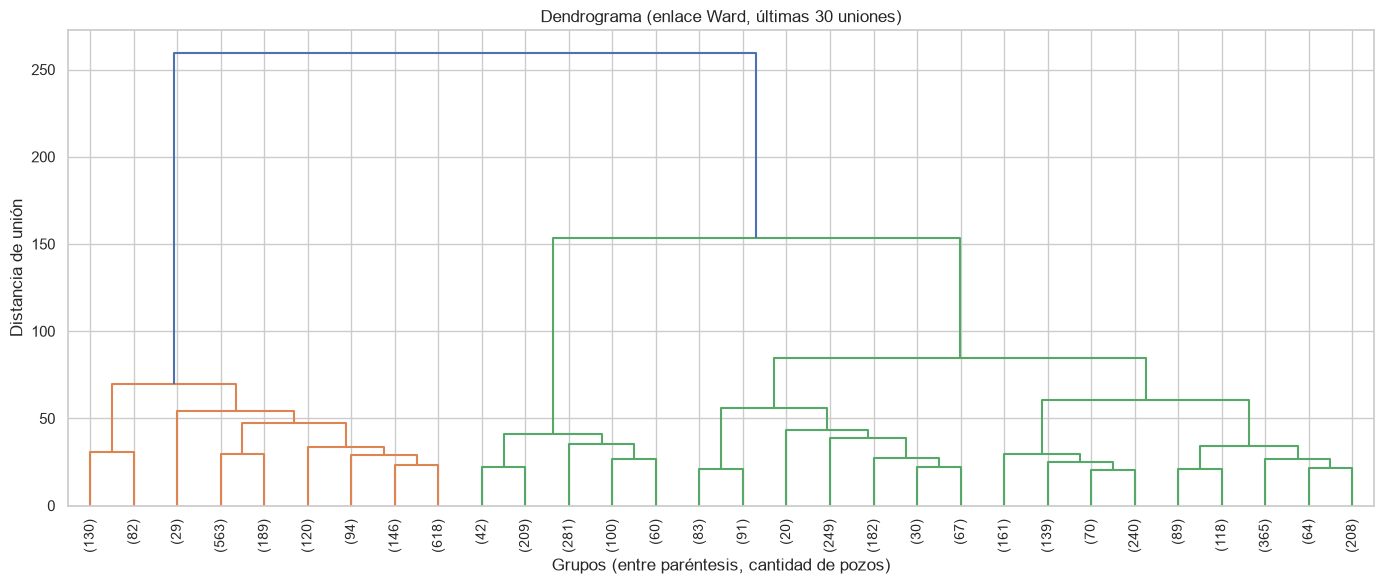

Distancias de las últimas uniones (de mayor a menor):
  pasar de 2 a 1 grupos: 259.4
  pasar de 3 a 2 grupos: 153.7
  pasar de 4 a 3 grupos: 84.7
  pasar de 5 a 4 grupos: 69.7
  pasar de 6 a 5 grupos: 60.4
  pasar de 7 a 6 grupos: 55.8
  pasar de 8 a 7 grupos: 54.2
  pasar de 9 a 8 grupos: 47.4


In [42]:
matriz_enlace = linkage(X_escalado.to_numpy(), method="ward")

fig, ax = plt.subplots(figsize=(14, 6))

dendrogram(
    matriz_enlace,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    color_threshold=None,
    ax=ax,
)

ax.set_title("Dendrograma (enlace Ward, últimas 30 uniones)")
ax.set_xlabel("Grupos (entre paréntesis, cantidad de pozos)")
ax.set_ylabel("Distancia de unión")

plt.tight_layout()
plt.show()

distancias_union = matriz_enlace[::-1, 2][:8]
print("Distancias de las últimas uniones (de mayor a menor):")
for cantidad_grupos, distancia in enumerate(distancias_union, start=1):
    print(f"  pasar de {cantidad_grupos + 1} a {cantidad_grupos} grupos: {distancia:,.1f}")

### 12.2. Comparación de la cantidad de grupos y del criterio de enlace

Evaluamos cortes de 2 a 8 grupos con dos criterios de enlace:

- **Ward**: une los grupos que menos aumentan la variación interna;
- **promedio** (`average`): une los grupos con menor distancia promedio entre sus pozos.

Para cada configuración calculamos las mismas métricas internas usadas con DBSCAN (silhouette, Calinski-Harabasz y Davies-Bouldin), el tamaño del grupo más chico y del más grande, y el ARI respecto de DBSCAN. El ARI se calcula solamente sobre los pozos que DBSCAN asignó a un grupo, porque el ruido no es un grupo comparable.

In [43]:
mascara_asignados_dbscan = etiquetas_candidato != -1
filas_jerarquico = []

for criterio_enlace in ["ward", "average"]:
    for cantidad_grupos in range(2, 9):
        etiquetas = AgglomerativeClustering(
            n_clusters=cantidad_grupos,
            linkage=criterio_enlace,
        ).fit_predict(X_escalado)

        tamanios = pd.Series(etiquetas).value_counts()

        filas_jerarquico.append({
            "enlace": criterio_enlace,
            "grupos": cantidad_grupos,
            "silueta": silhouette_score(X_escalado, etiquetas),
            "calinski_harabasz": calinski_harabasz_score(X_escalado, etiquetas),
            "davies_bouldin": davies_bouldin_score(X_escalado, etiquetas),
            "grupo_menor_%": 100 * tamanios.min() / len(etiquetas),
            "grupo_mayor_%": 100 * tamanios.max() / len(etiquetas),
            "ari_vs_dbscan": adjusted_rand_score(
                etiquetas_candidato[mascara_asignados_dbscan],
                etiquetas[mascara_asignados_dbscan],
            ),
        })

grilla_jerarquico = pd.DataFrame(filas_jerarquico)

display(grilla_jerarquico.round(3))

,enlace,grupos,silueta,calinski_harabasz,davies_bouldin,grupo_menor_%,grupo_mayor_%,ari_vs_dbscan
0,ward,2,0.389,"3,717.781",0.973,40.732,59.268,0.032
1,ward,3,0.373,"3,437.527",0.997,14.300,44.968,0.302
2,ward,4,0.355,"2,784.217",1.380,14.300,40.732,0.429
3,ward,5,0.311,"2,396.094",1.357,4.381,36.350,0.382
4,ward,6,0.262,"2,134.601",1.342,4.381,36.350,0.298
5,ward,7,0.271,"1,956.442",1.330,3.596,36.350,0.296
6,ward,8,0.279,"1,841.153",1.234,0.599,35.751,0.296
7,average,2,0.611,30.261,0.496,0.062,99.938,0.000
8,average,3,0.402,92.291,0.704,0.062,99.111,0.000
9,average,4,0.330,87.199,0.738,0.062,98.677,0.000


El enlace **promedio** no resulta útil: con hasta cinco grupos deja más del 97 % de los pozos en un único grupo y el resto en grupos de muy pocos pozos. Sus valores altos de silhouette con dos o tres grupos se deben justamente a que separa unos pocos pozos atípicos del resto, de manera similar a lo que ocurría con DBSCAN cuando `min_samples` era bajo. Por eso continuamos con el enlace **Ward**.

Con Ward, la silhouette disminuye a medida que aumenta la cantidad de grupos (0,389 con dos grupos, 0,373 con tres y 0,355 con cuatro) y cae más marcadamente a partir de cinco grupos. Davies-Bouldin también empeora a partir de cuatro grupos.

### 12.3. Selección de la cantidad de grupos

Elegimos **k = 4** con enlace Ward por las siguientes razones:

- mantiene métricas internas buenas (silhouette 0,355), superiores a las de DBSCAN sobre sus pozos asignados (0,272, ver sección 12.5);
- produce grupos de tamaño útil: el grupo más chico contiene el 14,3 % de los pozos y el más grande el 40,7 %;
- tiene la misma cantidad de grupos que DBSCAN, lo que facilita comparar ambas segmentaciones;
- obtiene el mayor ARI respecto de DBSCAN entre los cortes de Ward, es decir, conserva buena parte de la estructura que encontró DBSCAN;
- con tres grupos, los pozos de baja producción continua quedan mezclados con los pozos cuya producción se interrumpió; con cuatro grupos esos dos perfiles se separan (ver sección 12.4).

A partir de cinco grupos las métricas caen y aparecen grupos de menos del 5 % de los pozos.

In [44]:
CANTIDAD_GRUPOS_JERARQUICO = 4

modelo_jerarquico = AgglomerativeClustering(
    n_clusters=CANTIDAD_GRUPOS_JERARQUICO,
    linkage="ward",
)

etiquetas_jerarquico = modelo_jerarquico.fit_predict(X_escalado)

perfiles_candidato["cluster_jerarquico"] = etiquetas_jerarquico

display(resumen_tamanios(etiquetas_jerarquico))

,pozos,porcentaje
cluster,,
0,1971,40.730
1,1454,30.050
2,692,14.300
3,722,14.920


### 12.4. Perfiles de los grupos jerárquicos

Resumimos las principales variables productivas, físicas y categóricas de cada grupo, igual que hicimos con DBSCAN. Usamos la mediana para las variables productivas porque son muy asimétricas.

In [45]:
def categoria_principal(serie):
    frecuencias = serie.value_counts(normalize=True, dropna=False)
    return f"{frecuencias.index[0]} ({frecuencias.iloc[0] * 100:.0f} %)"


resumen_jerarquico = (
    perfiles_candidato
    .groupby("cluster_jerarquico")
    .agg(
        pozos=("idpozo", "count"),
        produccion_media_mediana=("produccion_media", "median"),
        produccion_acumulada_mediana=("produccion_acumulada", "median"),
        porcentaje_meses_productivos=("porcentaje_meses_productivos", "mean"),
        produccion_media_6m_mediana=("produccion_media_6m", "median"),
        meses_observados_mediana=("meses_observados", "median"),
        profundidad_mediana=("profundidad", "median"),
        tipo_pozo_principal=("tipopozo", categoria_principal),
        recurso_principal=("sub_tipo_recurso", categoria_principal),
        formacion_principal=("formacion", categoria_principal),
    )
    .round(1)
)

display(resumen_jerarquico)

,pozos,produccion_media_mediana,produccion_acumulada_mediana,porcentaje_meses_productivos,produccion_media_6m_mediana,meses_observados_mediana,profundidad_mediana,tipo_pozo_principal,recurso_principal,formacion_principal
cluster_jerarquico,,,,,,,,,,
0,1971,"1,689.700","55,137.200",94.200,848.000,35.000,"5,782.000",Petrolífero (83 %),SHALE (97 %),VACA MUERTA (97 %)
1,1454,25.800,"2,961.700",85.800,5.700,125.000,"3,077.000",Gasífero (74 %),TIGHT (67 %),VACA MUERTA (31 %)
2,692,0.000,0.000,0.700,0.000,104.000,"3,305.400",Gasífero (79 %),TIGHT (59 %),VACA MUERTA (37 %)
3,722,32.900,"4,004.400",50.300,0.000,120.000,"3,483.000",Gasífero (36 %),SHALE (75 %),VACA MUERTA (72 %)


Los cuatro grupos tienen perfiles claramente distintos:

- **Grupo 0 – pozos petrolíferos shale de alta producción** (1.971 pozos): la mayor producción media y acumulada, producción en casi todos los meses y la mayor producción reciente. Son pozos más jóvenes y profundos, mayormente petrolíferos de Vaca Muerta.
- **Grupo 1 – pozos maduros de baja producción continua** (1.454 pozos): producción de petróleo baja pero sostenida, con producción en la mayoría de los meses y una trayectoria larga. Predominan los pozos gasíferos y los recursos tight.
- **Grupo 2 – pozos sin producción de petróleo** (692 pozos): producción de petróleo prácticamente nula durante toda su historia. Son mayormente gasíferos y de recursos tight.
- **Grupo 3 – pozos con producción discontinua o interrumpida** (722 pozos): produjeron petróleo en una parte de su historia, pero no tienen producción reciente. Es el grupo más heterogéneo en tipo de pozo.

La numeración de los grupos es un identificador técnico y no representa un orden.

### 12.5. Comparación con DBSCAN

Comparamos ambas segmentaciones de dos maneras:

1. una **tabla cruzada** que muestra en qué grupo jerárquico quedó cada grupo de DBSCAN (incluido el ruido);
2. las **métricas internas** de ambos modelos. Como DBSCAN excluye el ruido de sus métricas, calculamos las del modelo jerárquico tanto sobre todos los pozos como sobre los mismos pozos que DBSCAN asignó a un grupo.

In [46]:
tabla_cruzada = pd.crosstab(
    perfiles_candidato["cluster_jerarquico"],
    perfiles_candidato["cluster"],
    rownames=["Grupo jerárquico"],
    colnames=["Grupo DBSCAN (-1 = ruido)"],
    margins=True,
    margins_name="Total",
)

display(tabla_cruzada)

X_asignados = X_escalado[mascara_asignados_dbscan]

comparacion_modelos = pd.DataFrame(
    {
        "DBSCAN (pozos asignados)": {
            "pozos evaluados": int(mascara_asignados_dbscan.sum()),
            "pozos sin grupo (ruido) %": 100 * (~mascara_asignados_dbscan).mean(),
            "grupo mayor %": 100 * pd.Series(etiquetas_candidato[mascara_asignados_dbscan]).value_counts().max() / len(etiquetas_candidato),
            "silueta": silhouette_score(X_asignados, etiquetas_candidato[mascara_asignados_dbscan]),
            "calinski_harabasz": calinski_harabasz_score(X_asignados, etiquetas_candidato[mascara_asignados_dbscan]),
            "davies_bouldin": davies_bouldin_score(X_asignados, etiquetas_candidato[mascara_asignados_dbscan]),
        },
        "Jerárquico (mismos pozos)": {
            "pozos evaluados": int(mascara_asignados_dbscan.sum()),
            "pozos sin grupo (ruido) %": np.nan,
            "grupo mayor %": np.nan,
            "silueta": silhouette_score(X_asignados, etiquetas_jerarquico[mascara_asignados_dbscan]),
            "calinski_harabasz": calinski_harabasz_score(X_asignados, etiquetas_jerarquico[mascara_asignados_dbscan]),
            "davies_bouldin": davies_bouldin_score(X_asignados, etiquetas_jerarquico[mascara_asignados_dbscan]),
        },
        "Jerárquico (todos los pozos)": {
            "pozos evaluados": len(etiquetas_jerarquico),
            "pozos sin grupo (ruido) %": 0.0,
            "grupo mayor %": 100 * pd.Series(etiquetas_jerarquico).value_counts().max() / len(etiquetas_jerarquico),
            "silueta": silhouette_score(X_escalado, etiquetas_jerarquico),
            "calinski_harabasz": calinski_harabasz_score(X_escalado, etiquetas_jerarquico),
            "davies_bouldin": davies_bouldin_score(X_escalado, etiquetas_jerarquico),
        },
    }
).T

display(comparacion_modelos.round(3))

print(
    "ARI entre ambos modelos (pozos asignados por DBSCAN): "
    f"{adjusted_rand_score(etiquetas_candidato[mascara_asignados_dbscan], etiquetas_jerarquico[mascara_asignados_dbscan]):.3f}"
)

Grupo DBSCAN (-1 = ruido),-1,0,1,2,3,Total
Grupo jerárquico,,,,,,
0,241,1730,0,0,0,1971
1,114,1340,0,0,0,1454
2,144,4,0,328,216,692
3,361,8,336,0,17,722
Total,860,3082,336,328,233,4839


,pozos evaluados,pozos sin grupo (ruido) %,grupo mayor %,silueta,calinski_harabasz,davies_bouldin
DBSCAN (pozos asignados),"3,979.000",17.772,63.691,0.272,"1,104.766",1.136
Jerárquico (mismos pozos),"3,979.000",NaN,NaN,0.424,"3,618.124",1.083
Jerárquico (todos los pozos),"4,839.000",0.000,40.732,0.355,"2,784.217",1.380


ARI entre ambos modelos (pozos asignados por DBSCAN): 0.429


### 12.6. Estabilidad del modelo jerárquico

Aplicamos el mismo procedimiento de la sección 10: en diez repeticiones seleccionamos aleatoriamente el 80 % de los pozos, volvemos a ajustar el modelo y comparamos sus etiquetas con las del modelo completo mediante el ARI.

In [47]:
rng_jerarquico = np.random.default_rng(RANDOM_STATE)
resultados_estabilidad_jerarquico = []

for repeticion in range(1, REPETICIONES + 1):
    indices_muestra = rng_jerarquico.choice(
        X_escalado.index,
        size=int(len(X_escalado) * PROPORCION_MUESTRA),
        replace=False,
    )

    etiquetas_muestra = AgglomerativeClustering(
        n_clusters=CANTIDAD_GRUPOS_JERARQUICO,
        linkage="ward",
    ).fit_predict(X_escalado.loc[indices_muestra])

    resultados_estabilidad_jerarquico.append({
        "repeticion": repeticion,
        "pozos_muestra": len(indices_muestra),
        "ari_vs_modelo_completo": adjusted_rand_score(
            perfiles_candidato.loc[indices_muestra, "cluster_jerarquico"],
            etiquetas_muestra,
        ),
    })

resultados_estabilidad_jerarquico = pd.DataFrame(resultados_estabilidad_jerarquico)

display(
    pd.DataFrame({
        "DBSCAN": resultados_estabilidad["ari_vs_modelo_completo"].agg(["mean", "std", "min", "max"]),
        "Jerárquico": resultados_estabilidad_jerarquico["ari_vs_modelo_completo"].agg(["mean", "std", "min", "max"]),
    }).round(3)
)

,DBSCAN,Jerárquico
mean,0.897,0.861
std,0.017,0.083
min,0.864,0.650
max,0.919,0.928


### 12.7. Conclusión de la comparación

Ambos modelos coinciden en la estructura general, pero el clustering jerárquico ofrece una segmentación más completa y más fácil de interpretar:

- **Asigna todos los pozos.** DBSCAN deja 860 pozos (17,77 %) como ruido; el modelo jerárquico los distribuye en los cuatro perfiles. La tabla cruzada muestra que la mayoría de esos pozos se suma a los grupos de producción interrumpida (361) y de alta producción (241).
- **Divide el grupo dominante de DBSCAN.** El cluster 0 de DBSCAN (3.082 pozos, 63,69 %) queda dividido en dos perfiles muy distintos: los pozos petrolíferos shale de alta producción (1.730 pozos) y los pozos maduros de baja producción continua (1.340 pozos). DBSCAN no los separa porque, en el espacio de las variables, forman una zona densa continua.
- **Conserva los grupos de DBSCAN que sí eran claros.** Los clusters 2 y 3 de DBSCAN (pozos sin producción de petróleo) quedan juntos en el grupo jerárquico 2, y el cluster 1 de DBSCAN queda dentro del grupo de producción interrumpida.
- **Mejores métricas internas.** Sobre los mismos 3.979 pozos que DBSCAN asignó a un grupo, el modelo jerárquico obtiene mayor silhouette (0,424 contra 0,272), mayor Calinski-Harabasz (3.618 contra 1.105) y menor Davies-Bouldin (1,083 contra 1,136).
- **Menor estabilidad.** Al reajustar con muestras del 80 % de los pozos, el ARI promedio del modelo jerárquico es 0,861 (mínimo 0,650), algo menor que el de DBSCAN (0,897, mínimo 0,864). Es decir, algunos pozos ubicados entre dos perfiles cambian de grupo según la muestra, especialmente en la frontera entre baja producción continua y producción interrumpida.

En conclusión, el modelo jerárquico con cuatro grupos complementa a DBSCAN: DBSCAN es más estable y permite detectar pozos atípicos como ruido, mientras que el modelo jerárquico produce una segmentación completa y separa perfiles productivos que DBSCAN agrupaba en un único cluster.

## 13. Conclusiones del análisis de clustering

Aplicamos DBSCAN sobre 4.839 perfiles de pozos, utilizando 16 variables numéricas transformadas y estandarizadas. La configuración seleccionada fue `eps=1,2` y `min_samples=24`.

El modelo identificó cuatro grupos y clasificó 860 pozos como ruido. La estabilidad fue adecuada: al trabajar con distintas muestras se obtuvo un ARI promedio de 0,897, lo que indica que la estructura principal se mantiene.

El Cluster 0 es el grupo más numeroso y presenta la mayor producción media y continuidad productiva. Está compuesto principalmente por pozos petrolíferos, asociados con la formación Vaca Muerta y recursos shale.

El Cluster 1 presenta una producción media menor y una continuidad más baja. Su composición es más heterogénea y contiene una proporción importante de pozos clasificados como `Otro tipo`.

Los Clusters 2 y 3 presentan una producción de petróleo prácticamente nula y muy pocos meses productivos. Ambos están compuestos principalmente por pozos gasíferos y muestran una mayor proporción de recursos tight. El Cluster 2 se relaciona especialmente con la formación Lajas, mientras que el Cluster 3 presenta mayor presencia de Vaca Muerta.

El ruido no debe interpretarse como un quinto grupo homogéneo. Está formado por perfiles que no alcanzaron la densidad necesaria para pertenecer a un cluster.

El análisis con PCA mostró que utilizar siete componentes generaba una segmentación muy desbalanceada, con más del 98 % de los pozos en un único grupo. Por este motivo, se mantuvo el modelo original como representación principal.

Como modelo alternativo aplicamos clustering jerárquico aglomerativo con enlace Ward sobre las mismas variables. Con cuatro grupos, asignó todos los pozos y separó el cluster dominante de DBSCAN en dos perfiles: pozos petrolíferos shale de alta producción y pozos maduros, mayormente gasíferos, de baja producción continua. Además identificó un grupo de pozos sin producción de petróleo y otro de pozos con producción interrumpida. Sobre los mismos pozos asignados por DBSCAN obtuvo mejores métricas internas (silhouette de 0,424 contra 0,272), aunque con una estabilidad algo menor (ARI promedio de 0,861 contra 0,897). Ambos modelos se presentan como complementarios.

## 14. Limitaciones del análisis

Los resultados obtenidos deben interpretarse considerando algunas limitaciones metodológicas.

- DBSCAN depende de la selección de `eps` y `min_samples`. Otros valores podrían producir una cantidad de grupos o un porcentaje de ruido diferente.
- El clustering se construyó utilizando variables numéricas seleccionadas previamente. La incorporación o exclusión de variables puede modificar las distancias y los grupos encontrados.
- Las variables productivas se resumieron en una fila por pozo. Esta transformación facilita la comparación, pero no conserva todos los detalles de la evolución mensual.
- La etiqueta `-1` representa ruido y no un grupo homogéneo. Por lo tanto, los pozos considerados ruido no deben interpretarse como un perfil único.
- Las variables categóricas se utilizaron después del clustering para describir los grupos. No se utilizaron para formar las distancias, por lo que las asociaciones observadas no implican causalidad.
- El estado, sistema de extracción y demás categorías representan el último registro disponible del pozo, no necesariamente toda su historia.
- Las métricas internas ayudan a comparar configuraciones, pero no determinan por sí solas cuál es el agrupamiento correcto.
- PCA permitió estudiar la estructura de los datos, pero la reducción a siete componentes generó grupos muy desbalanceados. Por eso se mantuvo el modelo original como principal.
- La estabilidad se evaluó mediante muestras aleatorias del 80 % de los perfiles. Este procedimiento respalda la consistencia del resultado, pero no elimina completamente la sensibilidad propia de DBSCAN.
- El clustering jerárquico requiere fijar la cantidad de grupos. Elegimos cuatro grupos a partir de las métricas internas, el dendrograma y la interpretabilidad, pero otros cortes también serían defendibles. Además, su estabilidad fue algo menor que la de DBSCAN, por lo que los pozos ubicados en la frontera entre dos perfiles deben interpretarse con cautela.

Por estas razones, los clusters deben interpretarse como perfiles descriptivos de los pozos y no como categorías definitivas ni como relaciones causales.

## 15. Exportación de resultados

Guardamos los resultados principales del clustering para poder utilizarlos en informes, gráficos y presentaciones sin tener que repetir todo el análisis.

Se exportan:

- la asignación de cada pozo a un grupo;
- el resumen productivo por cluster;
- la comparación de configuraciones;
- el resumen final de perfiles;
- la asignación, la grilla, los perfiles y la estabilidad del modelo jerárquico (columna `cluster_jerarquico` y archivos `*_jerarquico.csv`).

In [48]:
RUTA_RESULTADOS = RUTA_PROCESSED / "clustering"

RUTA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True,
)

perfiles_candidato.to_csv(
    RUTA_RESULTADOS / "perfiles_con_clusters.csv",
    index=False,
)

resumen_productivo_clusters.to_csv(
    RUTA_RESULTADOS / "resumen_productivo_clusters.csv"
)

grilla_resultados.to_csv(
    RUTA_RESULTADOS / "grilla_dbscan.csv",
    index=False,
)

grilla_resultados_pca.to_csv(
    RUTA_RESULTADOS / "grilla_dbscan_pca.csv",
    index=False,
)

resumen_perfiles.to_csv(
    RUTA_RESULTADOS / "resumen_perfiles.csv"
)

resultados_estabilidad.to_csv(
    RUTA_RESULTADOS / "estabilidad_dbscan.csv",
    index=False,
)

grilla_jerarquico.to_csv(
    RUTA_RESULTADOS / "grilla_jerarquico.csv",
    index=False,
)

resumen_jerarquico.to_csv(
    RUTA_RESULTADOS / "resumen_perfiles_jerarquico.csv"
)

comparacion_modelos.to_csv(
    RUTA_RESULTADOS / "comparacion_dbscan_jerarquico.csv"
)

resultados_estabilidad_jerarquico.to_csv(
    RUTA_RESULTADOS / "estabilidad_jerarquico.csv",
    index=False,
)

print(
    f"Resultados exportados en: {RUTA_RESULTADOS}"
)

Resultados exportados en: ../data/processed/clustering
